# 2.4b — VAE Geometric Shape Analysis

This notebook bridges the statistical analysis in 2.4 with the visual
inspection in notebook 12. It answers three questions:

1. **What physical shape feature does each significant VAE dimension control?**  
   We traverse each top-trending dimension from its 3rd-millennium mean to
   its 1st-millennium mean, decode each step into a silhouette, and measure
   classical shape descriptors (h/w ratio, solidity, eccentricity, compactness).
   The descriptor that changes most along the traversal *is* what that dimension controls.

2. **How did tablet shape evolve visually across 3,300 years?**  
   Decode the mean VAE vector for each period and display them as a
   chronological timeline of representative silhouettes.

3. **Which periods cluster by shape, and can we see why?**  
   Reproduce the dendrogram from notebook 11.1 but annotate each leaf with
   its decoded mean-period silhouette.

**Prerequisites:** Run notebooks 2.4 (generates `vae_dim_stats.csv` and
`vae_period_mean_vectors.csv`) and have the VAE checkpoint available
(either from `VAE_trained_model/` extracted from Zenodo, or `lightning_logs/`).

In [9]:
import os, sys, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.stats import spearmanr
import torch
from skimage.measure import label as sk_label, regionprops
from PIL import Image

sys.path.insert(0, '.')  # ensure local modules are importable
from VAE_model_tablets_class import VAE
from era_data import TabletPeriodDataset

warnings.filterwarnings('ignore')

FIGURES_DIR = 'paper/figures'
ZENODO_BASE = 'https://zenodo.org/records/12787746/files'
os.makedirs(FIGURES_DIR, exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 10, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'figure.dpi': 150, 'savefig.dpi': 300,
})

PERIOD_CHRON_ORDER = [
    'Uruk IV','Uruk III','Proto-Elamite',
    'ED I-II','ED IIIa','ED IIIb','Ebla',
    'Old Akkadian','Lagash II','Ur III',
    'Early Old Babylonian','Old Babylonian','Old Assyrian',
    'Middle Assyrian','Middle Babylonian','Middle Elamite','Hittite',
    'Neo-Assyrian','Neo-Babylonian','Achaemenid','Hellenistic',
]
PALETTE = {'3rd millennium BCE':'#4878CF','2nd millennium BCE':'#6ACC65','1st millennium BCE':'#D65F5F'}
THIRD_MIL  = {'Uruk III','Uruk IV','Proto-Elamite','ED I-II','ED IIIa','ED IIIb','Ebla','Old Akkadian','Lagash II','Ur III'}
SECOND_MIL = {'Early Old Babylonian','Old Babylonian','Old Assyrian','Middle Assyrian','Middle Babylonian','Middle Elamite','Hittite'}

def to_millennium(p):
    if p in THIRD_MIL:  return '3rd millennium BCE'
    if p in SECOND_MIL: return '2nd millennium BCE'
    return '1st millennium BCE'

VAE_DIMS = [f'X{i}' for i in range(1, 13)]
print('Setup complete.')

Setup complete.


## 1. Load VAE model

In [10]:
num_classes = len(TabletPeriodDataset.PERIOD_INDICES)

try:
    class_weights = torch.load('data/class_weights_period.pt')
    print('Loaded class_weights from file.')
except FileNotFoundError:
    class_weights = torch.ones(num_classes)
    print(f'Using uniform class_weights ({num_classes} classes) — correct for inference.')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
VERSION_NAME = ('period_clf_bs8_lr0.0001_beta_1_epochs_30'
                '-VAE-94936_samples-masked_w_classification_loss'
                '-equalpartsloss-April16_2')

def find_checkpoint(version_name):
    candidates = [
        f'lightning_logs/{version_name}/checkpoints/epoch=22-step=213621.ckpt',
        f'VAE_trained_model/{version_name}/checkpoints/epoch=22-step=213621.ckpt',
    ]
    for path in candidates:
        if os.path.exists(path):
            return path
    found = (glob.glob('VAE_trained_model/**/*.ckpt', recursive=True) +
             glob.glob('lightning_logs/**/*.ckpt', recursive=True))
    if found:
        return found[0]
    raise FileNotFoundError('No .ckpt found — run the download cell in notebook 12 first.')

checkpoint_path = find_checkpoint(VERSION_NAME)
print(f'Using checkpoint: {checkpoint_path}')

vae_model = VAE.load_from_checkpoint(
    checkpoint_path,
    image_channels=1, z_dim=12, lr=0.0001,
    use_classification_loss=True, num_classes=num_classes,
    loss_type='weighted', class_weights=class_weights, device=device
)
vae_model.eval()
print('VAE model loaded and set to eval mode.')

Using uniform class_weights (22 classes) — correct for inference.
Using checkpoint: VAE_trained_model/period_clf_bs8_lr0.0001_beta_1_epochs_30-VAE-94936_samples-masked_w_classification_loss-equalpartsloss-April16_2/checkpoints/epoch=22-step=213621.ckpt
VAE model loaded and set to eval mode.


## 2. Load statistics and encodings

In [11]:
# Dimension statistics from notebook 2.4
dim_stats = pd.read_csv(f'{FIGURES_DIR}/vae_dim_stats.csv', index_col='Dimension')
mean_vecs = pd.read_csv(f'{FIGURES_DIR}/vae_period_mean_vectors.csv', index_col='Period')

# Top dimensions
top_trend_dims = dim_stats['abs_rho'].nlargest(3).index.tolist()
top_disc_dims  = dim_stats['eta2'].nlargest(3).index.tolist()
print(f'Top trending dims (diachronic): {top_trend_dims}')
print(f'Top discriminating dims (KW):   {top_disc_dims}')
print()
print('Dimension statistics:')
print(dim_stats[['eta2','rho','sig','abs_rho']].sort_values('abs_rho', ascending=False).round(4).to_string())

# Raw encodings — needed for genre-controlled means
print('\nLoading VAE encodings from Zenodo...')
dfs = [pd.read_csv(f'{ZENODO_BASE}/vae_encoding_df_April16_w_class_{s}.csv')
       for s in ['train', 'val', 'test']]
vae_all = pd.concat(dfs, ignore_index=True)
vae_clean = vae_all[vae_all['Period_Name'].isin(PERIOD_CHRON_ORDER)].copy()
vae_clean['millennium'] = vae_clean['Period_Name'].apply(to_millennium)

# Genres for stratified analysis
FOCAL_GENRES = ['Administrative', 'Literary', 'Legal']
genre_counts = vae_clean['Genre_Name'].value_counts()
print('\nGenre distribution in corpus:')
print(genre_counts.to_string())

# Global mean (all tablets) — used as "other dimensions" baseline in traversals
global_mean = vae_clean[VAE_DIMS].mean().values
global_std  = vae_clean[VAE_DIMS].std().values

# Per-millennium mean for ALL tablets (baseline for full-corpus traversal)
mil_means_all = {}
for m in ['3rd millennium BCE', '2nd millennium BCE', '1st millennium BCE']:
    mil_means_all[m] = vae_clean[vae_clean['millennium']==m][VAE_DIMS].mean().values

# Per-millennium mean PER GENRE (baseline for genre-controlled traversal)
mil_means_genre = {}   # mil_means_genre[genre][millennium] = array
genre_means_all = {}   # genre_means_all[genre] = global mean for that genre
for genre in FOCAL_GENRES:
    sub = vae_clean[vae_clean['Genre_Name'] == genre]
    genre_means_all[genre] = sub[VAE_DIMS].mean().values
    mil_means_genre[genre] = {}
    for m in ['3rd millennium BCE', '2nd millennium BCE', '1st millennium BCE']:
        g = sub[sub['millennium'] == m]
        if len(g) >= 10:
            mil_means_genre[genre][m] = g[VAE_DIMS].mean().values
        else:
            mil_means_genre[genre][m] = None

# Per-period mean per genre (for genre-stratified timeline and dendrogram)
print('\nComputing genre × period mean vectors...')
genre_period_means = {}   # genre_period_means[genre][period] = array or None
for genre in FOCAL_GENRES:
    sub = vae_clean[vae_clean['Genre_Name'] == genre]
    genre_period_means[genre] = {}
    for p in PERIOD_CHRON_ORDER:
        g = sub[sub['Period_Name'] == p]
        if len(g) >= 10:
            genre_period_means[genre][p] = g[VAE_DIMS].mean().values
        else:
            genre_period_means[genre][p] = None

print('Done. Genre × period mean vectors ready.')
for genre in FOCAL_GENRES:
    n_periods = sum(1 for v in genre_period_means[genre].values() if v is not None)
    print(f'  {genre}: {n_periods} periods with ≥10 tablets')

Top trending dims (diachronic): ['X2', 'X8', 'X7']
Top discriminating dims (KW):   ['X7', 'X12', 'X6']

Dimension statistics:
             eta2     rho sig  abs_rho
Dimension                             
X2         0.0784  0.6545  **   0.6545
X8         0.0246 -0.5727  **   0.5727
X7         0.4346 -0.4299  ns   0.4299
X10        0.1715 -0.3623  ns   0.3623
X9         0.0581  0.2935  ns   0.2935
X1         0.0653 -0.2545  ns   0.2545
X12        0.3876  0.2104  ns   0.2104
X5         0.0710  0.1727  ns   0.1727
X3         0.0679  0.1597  ns   0.1597
X4         0.1992 -0.1026  ns   0.1026
X6         0.2416  0.0455  ns   0.0455
X11        0.0458 -0.0312  ns   0.0312

Loading VAE encodings from Zenodo...

Genre distribution in corpus:
Genre_Name
Administrative        42941
uncertain             22629
Letter                 5193
Legal                  4702
Royal/Monumental       4267
Literary               4094
Lexical                3225
Omen                   2422
School                 1

## 3. Helper functions: decode and measure shape

In [12]:
def decode_vector(z_vec, model):
    """
    Decode a 12-dim latent vector to a 512×512 numpy silhouette (float32, 0–1).
    """
    z = torch.tensor(z_vec.astype('float32')).unsqueeze(0)
    with torch.no_grad():
        h = model.fc3(z)
        img = model.decoder(h).squeeze().cpu().numpy()
    return img  # shape (512, 512)


def measure_shape(img, threshold=0.5):
    """
    Measure geometric descriptors from a decoded VAE silhouette.
    Returns a dict with:
      hw_ratio      : bounding-box height / width (>1 = portrait, <1 = landscape)
      solidity      : area / convex_hull_area  (1 = convex, <1 = concave/jagged)
      eccentricity  : ellipse eccentricity (0 = circle, →1 = elongated rod)
      compactness   : 4π × area / perimeter²  (1 = circle, <1 = irregular)
      area_fraction : proportion of pixels that are tablet
    """
    binary = (img > threshold).astype(np.uint8)
    labeled = sk_label(binary)
    if labeled.max() == 0:
        return {k: np.nan for k in
                ['hw_ratio','solidity','eccentricity','compactness','area_fraction']}
    props = sorted(regionprops(labeled), key=lambda r: r.area, reverse=True)[0]
    h = props.bbox[2] - props.bbox[0]
    w = props.bbox[3] - props.bbox[1]
    hw_ratio = h / w if w > 0 else np.nan
    compactness = ((4 * np.pi * props.area / props.perimeter**2)
                   if props.perimeter > 0 else np.nan)
    return {
        'hw_ratio':      hw_ratio,
        'solidity':      props.solidity,
        'eccentricity':  props.eccentricity,
        'compactness':   compactness,
        'area_fraction': props.area / binary.size,
    }


def traversal_vectors(dim_idx, baseline_vec, start_val, end_val, n_steps=11):
    """
    Generate n_steps latent vectors traversing dimension `dim_idx`
    from start_val to end_val, holding all other dimensions at `baseline_vec`.

    For genre-controlled traversal: pass the genre's global mean as baseline_vec,
    and the genre's 3rd-mil / 1st-mil mean values for that dimension as
    start_val / end_val.
    """
    step_vals = np.linspace(start_val, end_val, n_steps)
    vecs = np.tile(baseline_vec, (n_steps, 1))
    vecs[:, dim_idx] = step_vals
    return vecs, step_vals


print('Helper functions defined.')
print('Test decode + measure (global mean vector)...')
test_img  = decode_vector(global_mean, vae_model)
test_desc = measure_shape(test_img)
print(f'  Image shape: {test_img.shape}')
print(f'  Shape descriptors at global mean: {test_desc}')

Helper functions defined.
Test decode + measure (global mean vector)...
  Image shape: (512, 512)
  Shape descriptors at global mean: {'hw_ratio': 2.9148936170212765, 'solidity': np.float64(0.7524236983842011), 'eccentricity': 0.9612161260814123, 'compactness': np.float64(0.12460674045677567), 'area_fraction': np.float64(0.14388656616210938)}


## 4. Traversal filmstrip + descriptor curves — genre-controlled

For each top-trending dimension we run **four traversals in parallel**:

- **All tablets** (global baseline — for reference)
- **Administrative** genre baseline
- **Literary** genre baseline
- **Legal** genre baseline

In each case the traversal moves that dimension from the genre's 3rd-millennium
average to its 1st-millennium average, while holding *all other dimensions* at
the genre's own global mean (not the corpus-wide mean).

This is the genre-controlled version: it answers "what does this dimension
change *within* the Administrative tradition?" independently of the shape
differences that exist between genres.

The descriptor with the highest Spearman |rho| along the traversal formally
identifies what that dimension controls.

In [13]:
N_STEPS   = 11
DESCS     = ['hw_ratio', 'solidity', 'eccentricity', 'compactness', 'area_fraction']
DESC_LABELS = {
    'hw_ratio':      'H/W ratio (>1 portrait)',
    'solidity':      'Solidity (convexity)',
    'eccentricity':  'Eccentricity (ellipse elongation)',
    'compactness':   'Compactness (circularity)',
    'area_fraction': 'Area fraction (tablet fill)',
}
GENRE_COLORS = {'All tablets': '#555555',
                'Administrative': '#2166AC',
                'Literary': '#D6604D',
                'Legal': '#4DAC26'}
GENRE_LS     = {'All tablets': '-', 'Administrative': '-', 'Literary': '--', 'Legal': '-.'}
DESC_COLORS  = ['#2166AC','#D6604D','#4DAC26','#8E44AD','#E67E22']

def build_traversal_spec(dim_idx, genre=None):
    """
    Returns (baseline_vec, start_val, end_val, full_start, full_end).
    
    baseline_vec         : all other dimensions held here
    start_val / end_val  : millennium-range endpoints (3rd-mil → 1st-mil mean)
                           used for descriptor-curve direction labelling only
    full_start / full_end: ±2σ endpoints for filmstrip (guarantees visible image change)
                           oriented in the historical direction (lower value first if
                           the historical trend is increasing, higher first if decreasing)
    """
    if genre is None:
        baseline  = global_mean.copy()
        m3_val    = mil_means_all['3rd millennium BCE'][dim_idx]
        m1_val    = mil_means_all['1st millennium BCE'][dim_idx]
    else:
        baseline  = genre_means_all[genre].copy()
        m3 = mil_means_genre[genre].get('3rd millennium BCE')
        m1 = mil_means_genre[genre].get('1st millennium BCE')
        if m3 is None or m1 is None:
            return None
        m3_val, m1_val = m3[dim_idx], m1[dim_idx]

    # Full ±2σ range, oriented so the filmstrip runs 3rd-mil-like → 1st-mil-like
    sigma      = global_std[dim_idx]
    center     = global_mean[dim_idx]
    low_val    = center - 2 * sigma
    high_val   = center + 2 * sigma
    # If the historical change is increasing (m1 > m3), go low→high; else high→low
    if m1_val >= m3_val:
        full_start, full_end = low_val, high_val
    else:
        full_start, full_end = high_val, low_val

    return baseline, m3_val, m1_val, full_start, full_end


# Run traversals — use full ±2σ range for both filmstrip and descriptor measurement
all_traversal_data = {}
TRAVERSAL_LABELS = ['All tablets'] + FOCAL_GENRES

for dim in top_trend_dims:
    dim_idx = VAE_DIMS.index(dim)
    all_traversal_data[dim] = {}
    for label in TRAVERSAL_LABELS:
        genre_key = None if label == 'All tablets' else label
        spec = build_traversal_spec(dim_idx, genre_key)
        if spec is None:
            print(f'  {dim} / {label}: insufficient data, skipped.')
            continue
        baseline, m3_val, m1_val, full_start, full_end = spec

        # Build vectors along the full range (±2σ) with genre baseline
        step_vals = np.linspace(full_start, full_end, N_STEPS)
        vecs = np.tile(baseline, (N_STEPS, 1))
        vecs[:, dim_idx] = step_vals

        images, descriptors = [], []
        print(f'Decoding {N_STEPS} steps for {dim} / {label} '
              f'(range {full_start:.2f}→{full_end:.2f})...', end=' ')
        for vec in vecs:
            img = decode_vector(vec, vae_model)
            images.append(img)
            descriptors.append(measure_shape(img))
        print('done.')

        all_traversal_data[dim][label] = {
            'step_vals':  step_vals,
            'mil_range':  (m3_val, m1_val),   # for annotations
            'images':     images,
            'descs':      pd.DataFrame(descriptors),
        }

print('\nAll genre-controlled traversals complete.')

Decoding 11 steps for X2 / All tablets (range -4.96→3.85)... done.
Decoding 11 steps for X2 / Administrative (range -4.96→3.85)... done.
Decoding 11 steps for X2 / Literary (range -4.96→3.85)... done.
Decoding 11 steps for X2 / Legal (range -4.96→3.85)... done.
Decoding 11 steps for X8 / All tablets (range 2.72→-3.23)... done.
Decoding 11 steps for X8 / Administrative (range 2.72→-3.23)... done.
Decoding 11 steps for X8 / Literary (range 2.72→-3.23)... done.
Decoding 11 steps for X8 / Legal (range 2.72→-3.23)... done.
Decoding 11 steps for X7 / All tablets (range -4.28→3.94)... done.
Decoding 11 steps for X7 / Administrative (range 3.94→-4.28)... done.
Decoding 11 steps for X7 / Literary (range -4.28→3.94)... done.
Decoding 11 steps for X7 / Legal (range 3.94→-4.28)... done.

All genre-controlled traversals complete.


In [14]:
# Identify the primary descriptor per dimension per genre
print('=== PRIMARY DESCRIPTOR PER DIMENSION × GENRE ===\n')
for dim in top_trend_dims:
    rho_val = dim_stats.loc[dim, 'rho']
    eta2    = dim_stats.loc[dim, 'eta2']
    print(f'{dim}  (corpus Spearman rho={rho_val:+.3f}, KW eta2={eta2:.4f}):')
    dim_primaries = {}
    for label in TRAVERSAL_LABELS:
        if label not in all_traversal_data[dim]:
            continue
        td = all_traversal_data[dim][label]
        x  = np.arange(N_STEPS)
        rhos = {}
        for desc in DESCS:
            vals = td['descs'][desc].values
            if not np.all(np.isnan(vals)):
                r, _ = spearmanr(x, vals)
                rhos[desc] = abs(r)
        if rhos:
            primary = max(rhos, key=rhos.get)
            dim_primaries[label] = primary
            # Store on the nested dict
            all_traversal_data[dim][label]['primary_descriptor'] = primary
            print(f'  {label:20s}: primary = {primary:20s}  '
                  + '  '.join(f'{d}={v:.2f}' for d, v in
                               sorted(rhos.items(), key=lambda kv: -kv[1])))
    primaries_set = set(dim_primaries.values())
    if len(primaries_set) == 1:
        print(f'  => CONSISTENT across all genres: {list(primaries_set)[0]}')
    else:
        print(f'  => INCONSISTENT across genres: {dim_primaries}')
        print(f'     (the dimension\'s physical meaning differs across scribal traditions)')
    print()

=== PRIMARY DESCRIPTOR PER DIMENSION × GENRE ===

X2  (corpus Spearman rho=+0.654, KW eta2=0.0784):
  All tablets         : primary = area_fraction         area_fraction=0.92  solidity=0.85  compactness=0.77  hw_ratio=0.25  eccentricity=0.16
  Administrative      : primary = area_fraction         area_fraction=0.99  solidity=0.65  compactness=0.54  hw_ratio=0.31  eccentricity=0.05
  Literary            : primary = solidity              solidity=0.79  compactness=0.75  hw_ratio=0.58  eccentricity=0.45  area_fraction=0.31
  Legal               : primary = area_fraction         area_fraction=1.00  solidity=0.79  compactness=0.75  eccentricity=0.41  hw_ratio=0.23
  => INCONSISTENT across genres: {'All tablets': 'area_fraction', 'Administrative': 'area_fraction', 'Literary': 'solidity', 'Legal': 'area_fraction'}
     (the dimension's physical meaning differs across scribal traditions)

X8  (corpus Spearman rho=-0.573, KW eta2=0.0246):
  All tablets         : primary = solidity              

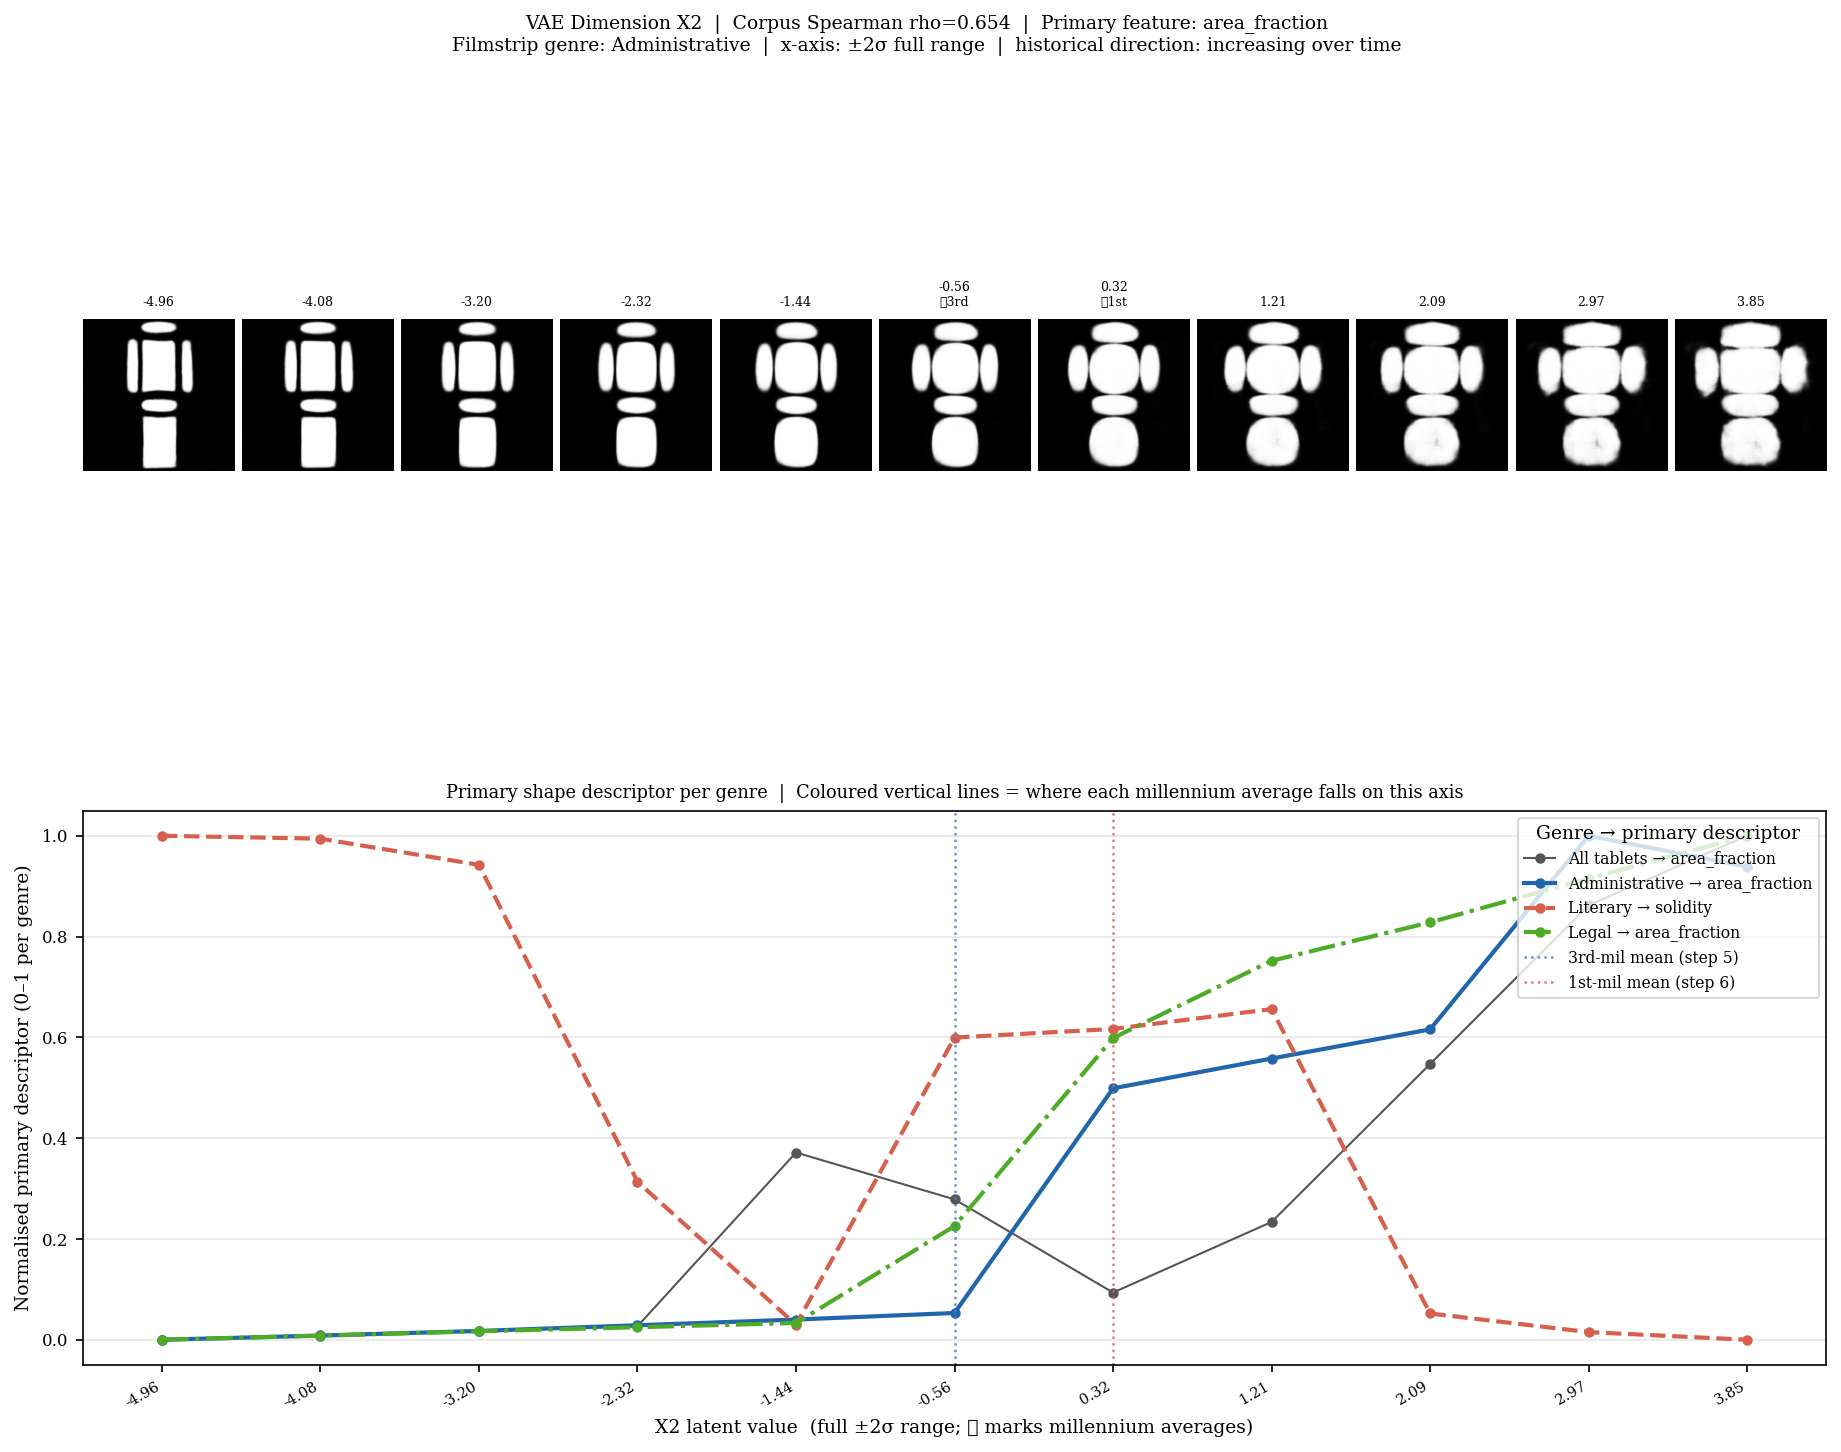

Saved: paper/figures/fig_vae_traversal_X2_genre.pdf


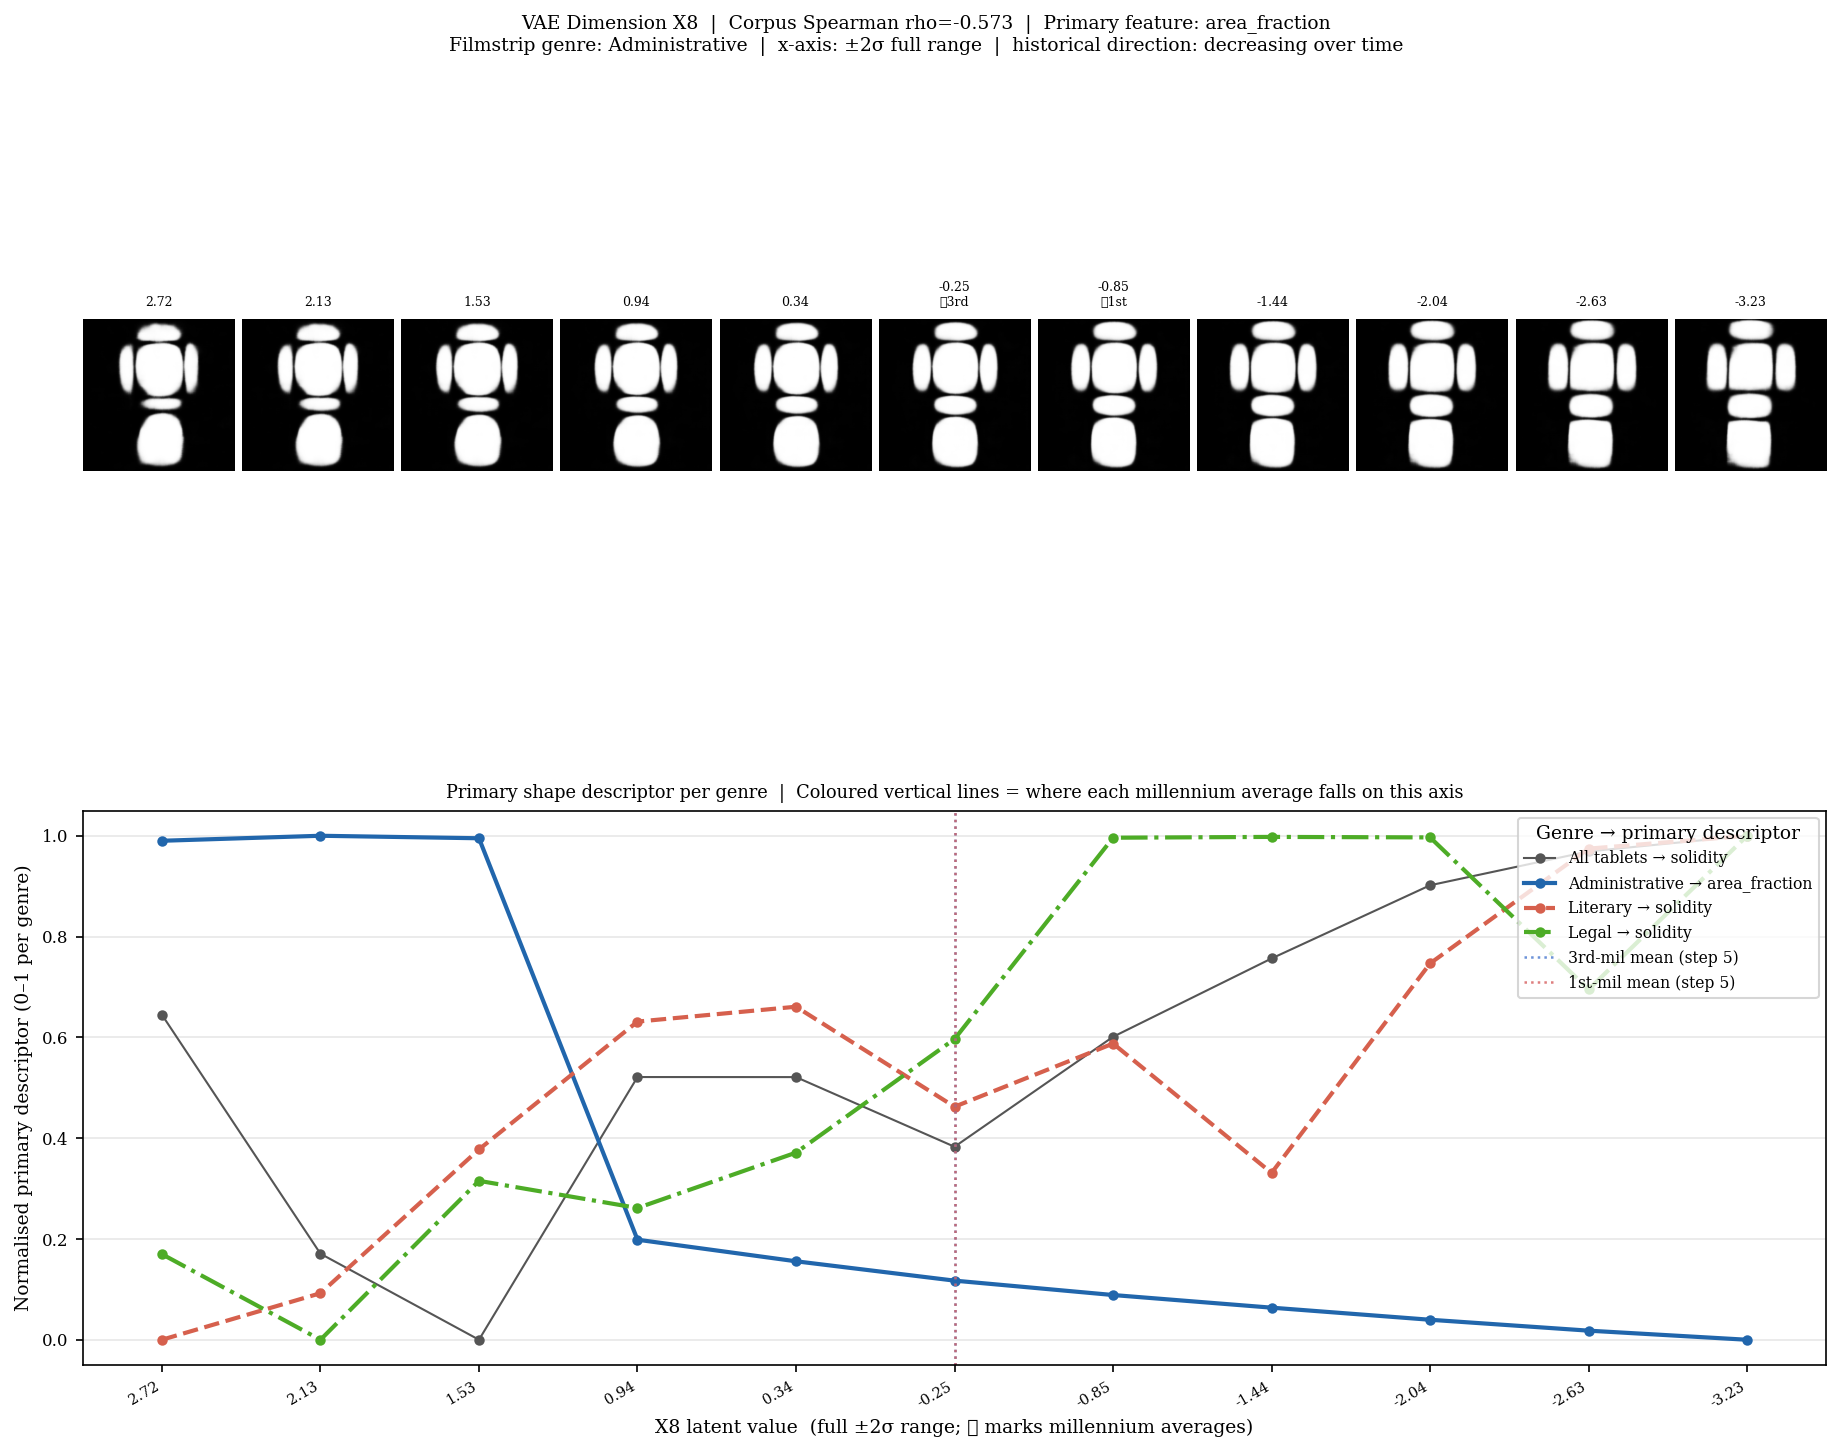

Saved: paper/figures/fig_vae_traversal_X8_genre.pdf


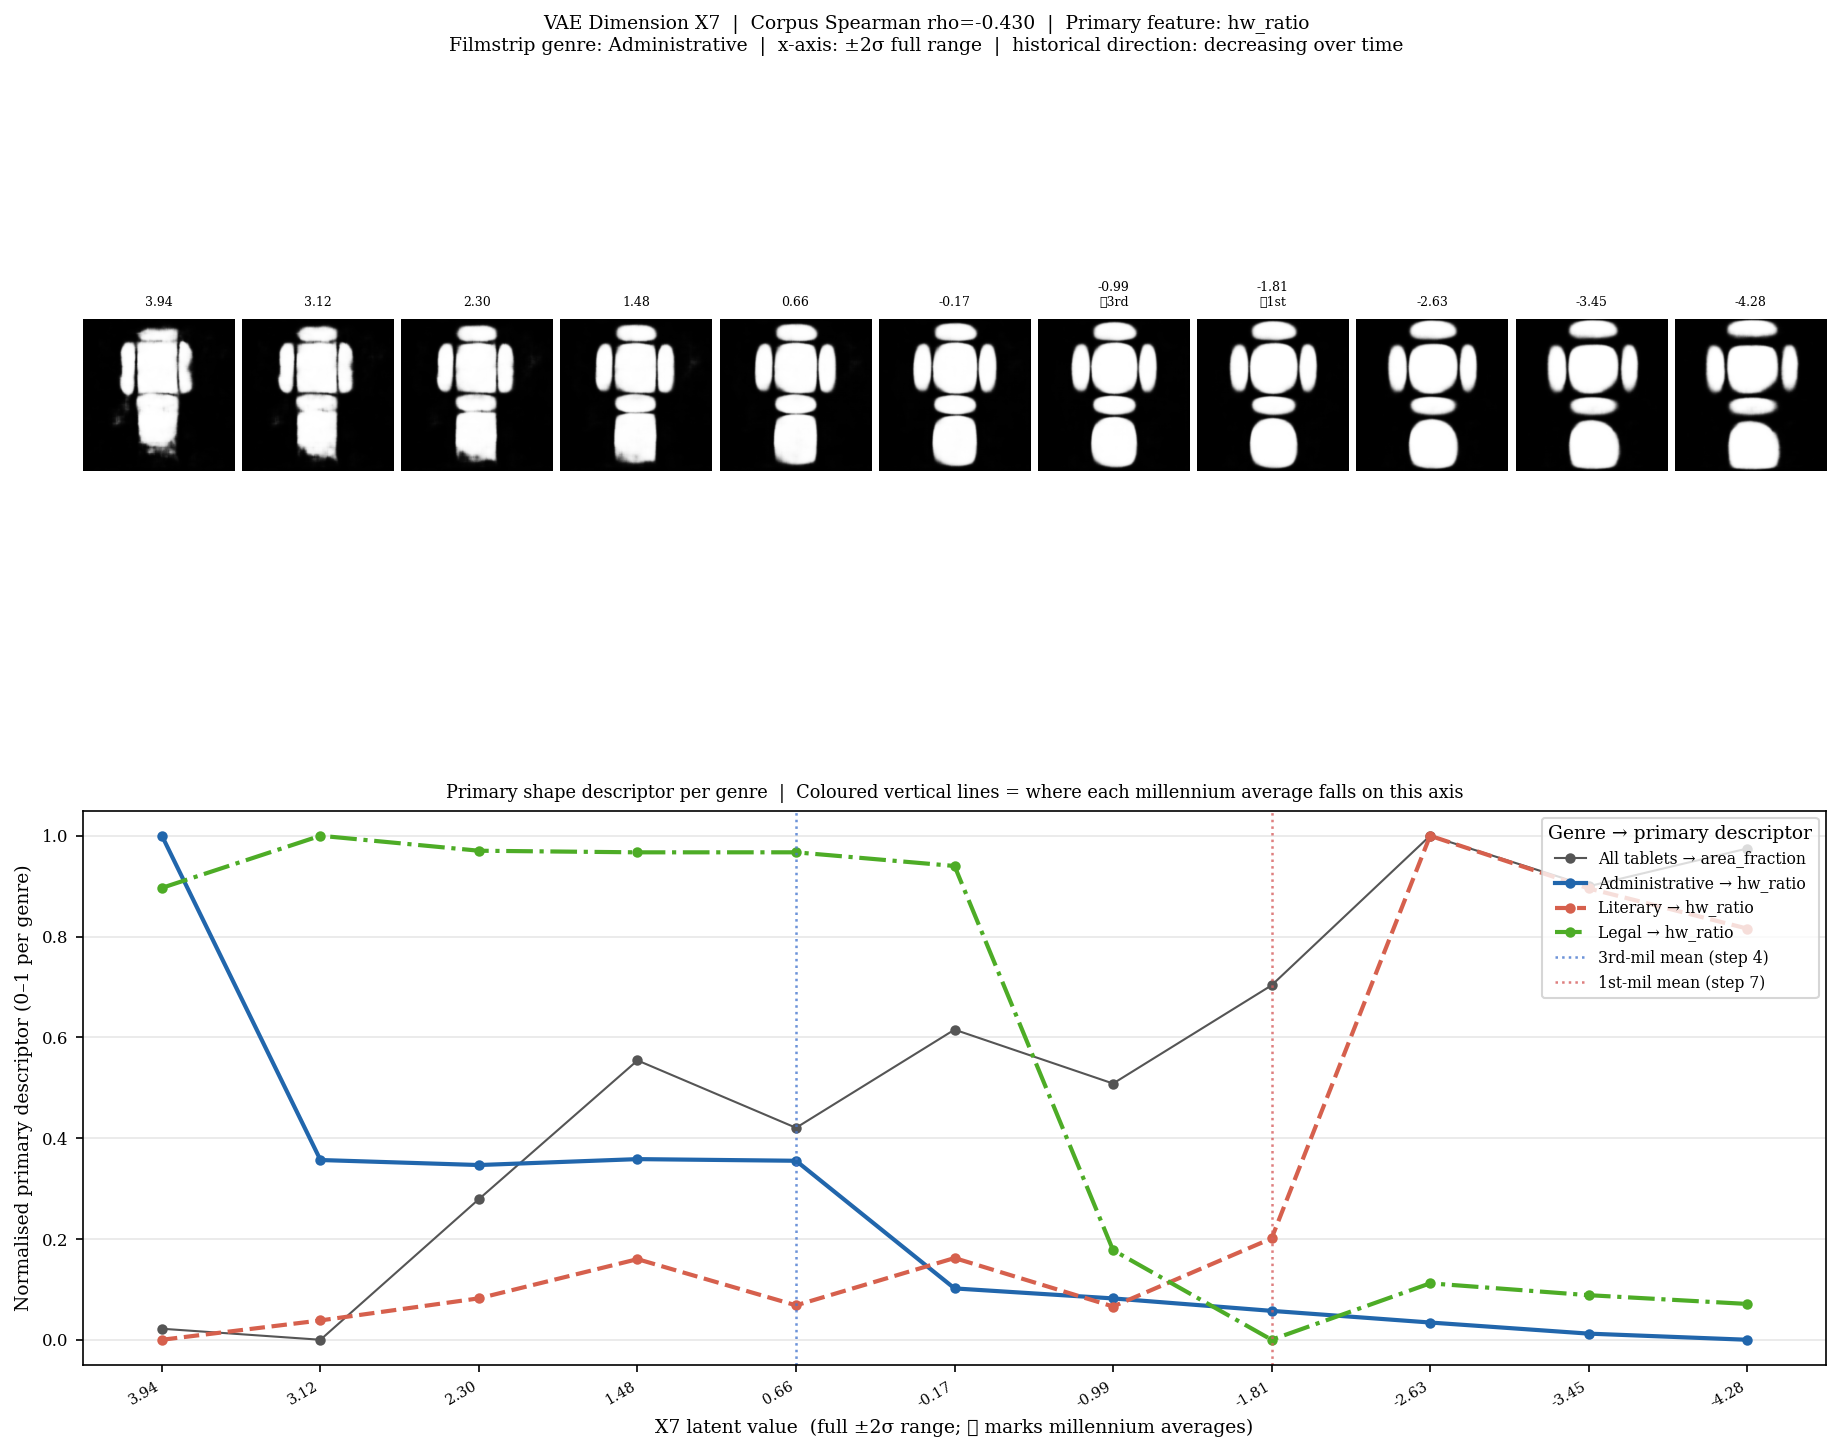

Saved: paper/figures/fig_vae_traversal_X7_genre.pdf


In [15]:
for dim in top_trend_dims:
    rho_val   = dim_stats.loc[dim, 'rho']
    direction = 'decreasing' if rho_val < 0 else 'increasing'

    filmstrip_key = 'Administrative' if 'Administrative' in all_traversal_data[dim] else 'All tablets'
    td_film = all_traversal_data[dim][filmstrip_key]
    primary = td_film.get('primary_descriptor', DESCS[0])
    m3_val, m1_val = td_film['mil_range']
    step_vals = td_film['step_vals']

    fig = plt.figure(figsize=(15, 10))
    fig.suptitle(
        f'VAE Dimension {dim}  |  Corpus Spearman rho={rho_val:.3f}  |  '
        f'Primary feature: {primary}\n'
        f'Filmstrip genre: {filmstrip_key}  |  '
        f'x-axis: ±2σ full range  |  historical direction: {direction} over time',
        fontsize=9, y=1.01
    )

    gs = fig.add_gridspec(2, N_STEPS, height_ratios=[2, 3], hspace=0.5, wspace=0.05)

    # Row 1: filmstrip
    for i, img in enumerate(td_film['images']):
        ax_img = fig.add_subplot(gs[0, i])
        ax_img.imshow(img, cmap='gray', vmin=0, vmax=1)
        ax_img.axis('off')
        sv = step_vals[i]
        # Mark if this step is closest to a millennium mean
        mark = ''
        if abs(sv - m3_val) == min(abs(step_vals - m3_val)):
            mark = '\n★3rd'
        elif abs(sv - m1_val) == min(abs(step_vals - m1_val)):
            mark = '\n★1st'
        ax_img.set_title(f'{sv:.2f}{mark}', fontsize=6)

    # Row 2: descriptor curves per genre (primary descriptor only, normalised 0–1)
    ax_desc = fig.add_subplot(gs[1, :])
    x = np.arange(N_STEPS)

    for label in TRAVERSAL_LABELS:
        if label not in all_traversal_data[dim]:
            continue
        td   = all_traversal_data[dim][label]
        prim = td.get('primary_descriptor', DESCS[0])
        vals = td['descs'][prim].values.astype(float)
        if np.all(np.isnan(vals)):
            continue
        vmin, vmax = np.nanmin(vals), np.nanmax(vals)
        normed = (vals - vmin) / (vmax - vmin) if vmax > vmin else np.zeros_like(vals)
        lw = 2.0 if label != 'All tablets' else 1.0
        ax_desc.plot(x, normed,
                     color=GENRE_COLORS[label], ls=GENRE_LS[label],
                     lw=lw, marker='o', ms=4,
                     label=f'{label} → {prim}')

    # Mark millennium positions on x-axis (using All tablets or filmstrip key)
    td_ref = all_traversal_data[dim].get('All tablets', td_film)
    sv_ref = td_ref['step_vals']
    m3_ref, m1_ref = td_ref['mil_range']
    i3 = int(np.argmin(np.abs(sv_ref - m3_ref)))
    i1 = int(np.argmin(np.abs(sv_ref - m1_ref)))
    ax_desc.axvline(i3, color='#4878CF', ls=':', lw=1.2, alpha=0.8, label=f'3rd-mil mean (step {i3})')
    ax_desc.axvline(i1, color='#D65F5F', ls=':', lw=1.2, alpha=0.8, label=f'1st-mil mean (step {i1})')

    ax_desc.set_xticks(x)
    ax_desc.set_xticklabels([f'{v:.2f}' for v in td_film['step_vals']], rotation=30, ha='right', fontsize=7)
    ax_desc.set_xlabel(f'{dim} latent value  (full ±2σ range; ★ marks millennium averages)')
    ax_desc.set_ylabel('Normalised primary descriptor (0–1 per genre)')
    ax_desc.set_title(
        'Primary shape descriptor per genre  |  '
        'Coloured vertical lines = where each millennium average falls on this axis',
        fontsize=8.5
    )
    ax_desc.legend(loc='upper right', fontsize=7.5, title='Genre → primary descriptor')
    ax_desc.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    outpath = f'{FIGURES_DIR}/fig_vae_traversal_{dim}_genre.pdf'
    plt.savefig(outpath, bbox_inches='tight')
    plt.show()
    print(f'Saved: {outpath}')

In [16]:
print('=== DIMENSION INTERPRETATION SUMMARY ===')
print('(Based on which shape descriptor changes most monotonically along ±2σ traversal)')
print()
for dim in top_trend_dims:
    rho  = dim_stats.loc[dim, 'rho']
    eta2 = dim_stats.loc[dim, 'eta2']
    sig  = dim_stats.loc[dim, 'sig']
    direction = 'DECREASES' if rho < 0 else 'INCREASES'
    print(f'{dim}:  rho={rho:+.3f} {sig}  eta2={eta2:.4f}')
    for label in TRAVERSAL_LABELS:
        if label not in all_traversal_data.get(dim, {}):
            continue
        prim = all_traversal_data[dim][label].get('primary_descriptor', '?')
        m3v, m1v = all_traversal_data[dim][label]['mil_range']
        print(f'  {label:20s}: primary = {prim:20s}  '
              f'(3rd-mil avg={m3v:.3f}, 1st-mil avg={m1v:.3f}, {direction})')
    print(f'  => Record this interpretation in notebook 12 for the paper.')
    print()

=== DIMENSION INTERPRETATION SUMMARY ===
(Based on which shape descriptor changes most monotonically along ±2σ traversal)

X2:  rho=+0.654 **  eta2=0.0784
  All tablets         : primary = area_fraction         (3rd-mil avg=-0.965, 1st-mil avg=0.204, INCREASES)
  Administrative      : primary = area_fraction         (3rd-mil avg=-0.995, 1st-mil avg=0.652, INCREASES)
  Literary            : primary = solidity              (3rd-mil avg=-2.768, 1st-mil avg=-0.271, INCREASES)
  Legal               : primary = area_fraction         (3rd-mil avg=-1.548, 1st-mil avg=0.539, INCREASES)
  => Record this interpretation in notebook 12 for the paper.

X8:  rho=-0.573 **  eta2=0.0246
  All tablets         : primary = solidity              (3rd-mil avg=-0.099, 1st-mil avg=-0.291, DECREASES)
  Administrative      : primary = area_fraction         (3rd-mil avg=-0.144, 1st-mil avg=-0.660, DECREASES)
  Literary            : primary = solidity              (3rd-mil avg=0.973, 1st-mil avg=-0.462, DECREASES

## 5. Decoded mean-period timeline

Decode the mean VAE vector for each period and display all 21 periods
in strict chronological order. This gives a direct visual of the shape
evolution over 3,300 years — one canonical representative silhouette
per period, derived from the mathematical average of all tablets in that period.

In [17]:
# Decode mean vector for every period — ALL tablets
periods_present = [p for p in PERIOD_CHRON_ORDER if p in mean_vecs.index]
print(f'Decoding period mean vectors (all tablets): {len(periods_present)} periods...')

decoded_means = {}    # decoded_means[period] = image array
shape_at_mean = {}    # shape_at_mean[period] = descriptor dict

for p in periods_present:
    vec = mean_vecs.loc[p, VAE_DIMS].values.astype('float32')
    img = decode_vector(vec, vae_model)
    decoded_means[p] = img
    shape_at_mean[p] = measure_shape(img)

# Decode mean vector per genre × period
print('\nDecoding genre × period mean vectors...')
decoded_genre = {}     # decoded_genre[genre][period] = image array
shape_genre   = {}     # shape_genre[genre][period]   = descriptor dict

for genre in FOCAL_GENRES:
    decoded_genre[genre] = {}
    shape_genre[genre]   = {}
    for p in PERIOD_CHRON_ORDER:
        vec = genre_period_means[genre].get(p)
        if vec is not None:
            img = decode_vector(vec, vae_model)
            decoded_genre[genre][p] = img
            shape_genre[genre][p]   = measure_shape(img)

print('Done.')
for genre in FOCAL_GENRES:
    n = len(decoded_genre[genre])
    print(f'  {genre}: {n} periods decoded')

# All-tablet shape descriptor table
shape_df = pd.DataFrame(shape_at_mean).T.reindex(periods_present)
shape_df['millennium'] = [to_millennium(p) for p in shape_df.index]
print('\nShape descriptors at all-tablet period mean:')
print(shape_df.round(3).to_string())

Decoding period mean vectors (all tablets): 21 periods...

Decoding genre × period mean vectors...
Done.
  Administrative: 19 periods decoded
  Literary: 8 periods decoded
  Legal: 11 periods decoded

Shape descriptors at all-tablet period mean:
                      hw_ratio  solidity  eccentricity  compactness  area_fraction          millennium
Uruk IV                  1.597     0.823         0.831        0.335          0.085  3rd millennium BCE
Uruk III                 2.072     0.757         0.924        0.221          0.255  3rd millennium BCE
Proto-Elamite            1.953     0.773         0.918        0.214          0.278  3rd millennium BCE
ED I-II                  1.198     0.871         0.485        0.333          0.057  3rd millennium BCE
ED IIIa                  1.029     0.805         0.530        0.291          0.150  3rd millennium BCE
ED IIIb                  1.025     0.814         0.411        0.302          0.140  3rd millennium BCE
Ebla                     1.411   

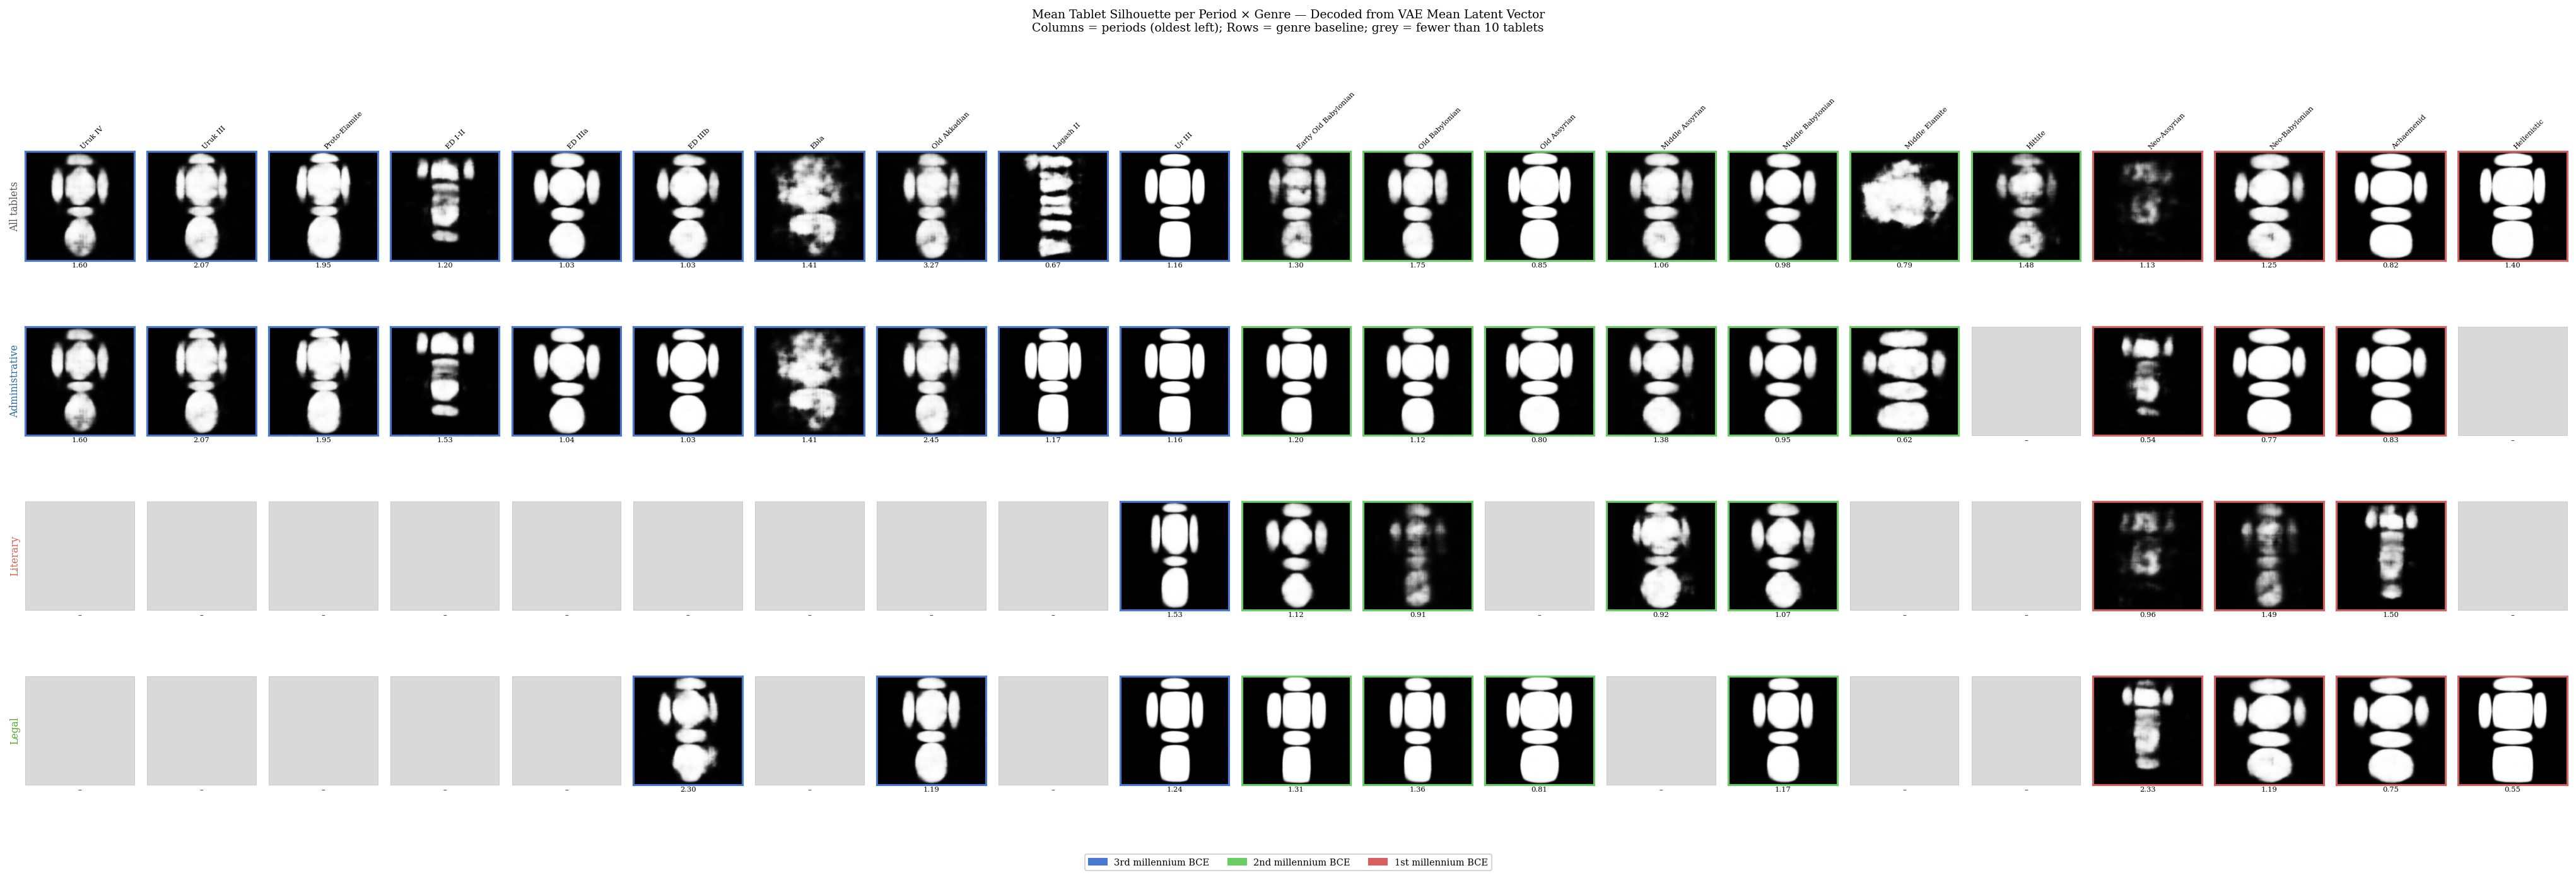

Saved: paper/figures/fig_vae_mean_period_timeline_genre.pdf


In [18]:
# Figure: genre-stratified chronological timeline
# Rows: All tablets, Administrative, Literary, Legal
# Columns: 21 periods in chronological order
# Each cell shows the decoded mean silhouette; grey = no data (< 10 tablets)

ROWS = ['All tablets'] + FOCAL_GENRES
ROW_DECODED = {
    'All tablets':    decoded_means,
    'Administrative': decoded_genre['Administrative'],
    'Literary':       decoded_genre['Literary'],
    'Legal':          decoded_genre['Legal'],
}
ROW_SHAPE = {
    'All tablets':    shape_at_mean,
    'Administrative': shape_genre['Administrative'],
    'Literary':       shape_genre['Literary'],
    'Legal':          shape_genre['Legal'],
}

n_periods = len(periods_present)
n_rows    = len(ROWS)

fig, axes = plt.subplots(n_rows, n_periods,
                         figsize=(n_periods * 1.3, n_rows * 2.2),
                         squeeze=False)
fig.suptitle(
    'Mean Tablet Silhouette per Period × Genre — Decoded from VAE Mean Latent Vector\n'
    'Columns = periods (oldest left); Rows = genre baseline; grey = fewer than 10 tablets',
    fontsize=9, y=1.01
)

# Column headers (period names) — once at the top
for col, p in enumerate(periods_present):
    axes[0, col].set_title(p, fontsize=5.5, rotation=45, ha='left', pad=2)

for row_idx, row_label in enumerate(ROWS):
    row_color = GENRE_COLORS.get(row_label, '#555555')
    # Row label on the left
    axes[row_idx, 0].set_ylabel(row_label, fontsize=7.5,
                                 color=row_color, labelpad=4, rotation=90)
    for col, p in enumerate(periods_present):
        ax = axes[row_idx, col]
        img_dict = ROW_DECODED[row_label]
        shp_dict = ROW_SHAPE[row_label]

        if p in img_dict:
            img = img_dict[p]
            hw  = shp_dict[p].get('hw_ratio', np.nan)
            ax.imshow(img, cmap='gray', vmin=0, vmax=1)
            ax.set_xlabel(f'{hw:.2f}', fontsize=5.5, labelpad=1)
            mil = to_millennium(p)
            for spine in ax.spines.values():
                spine.set_edgecolor(PALETTE[mil])
                spine.set_linewidth(1.5)
        else:
            # No data: grey placeholder
            ax.imshow(np.ones((10, 10)) * 0.85, cmap='gray', vmin=0, vmax=1)
            ax.set_xlabel('–', fontsize=5.5, labelpad=1)
            for spine in ax.spines.values():
                spine.set_edgecolor('#cccccc')
                spine.set_linewidth(0.5)
        ax.set_xticks([]); ax.set_yticks([])

# Millennium colour legend
handles = [mpatches.Patch(color=v, label=k) for k, v in PALETTE.items()]
fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=7,
           bbox_to_anchor=(0.5, -0.03))

plt.tight_layout()
outpath = f'{FIGURES_DIR}/fig_vae_mean_period_timeline_genre.pdf'
plt.savefig(outpath, bbox_inches='tight', dpi=200)
plt.show()
print(f'Saved: {outpath}')

## 6. Dendrogram annotated with decoded silhouettes

The pairwise Euclidean distance matrix in notebook 2.4 section 8 summarises
how similar periods are in the full 12-dimensional shape space. Here we
reconstruct that dendrogram and place the decoded mean-period silhouette
at each leaf, so the reader can *see* why clusters form.

For example: if Ur III and Early Old Babylonian cluster together, their
leaf images should look visually similar; if Uruk IV is an isolated outlier,
its image should look distinct from all others.

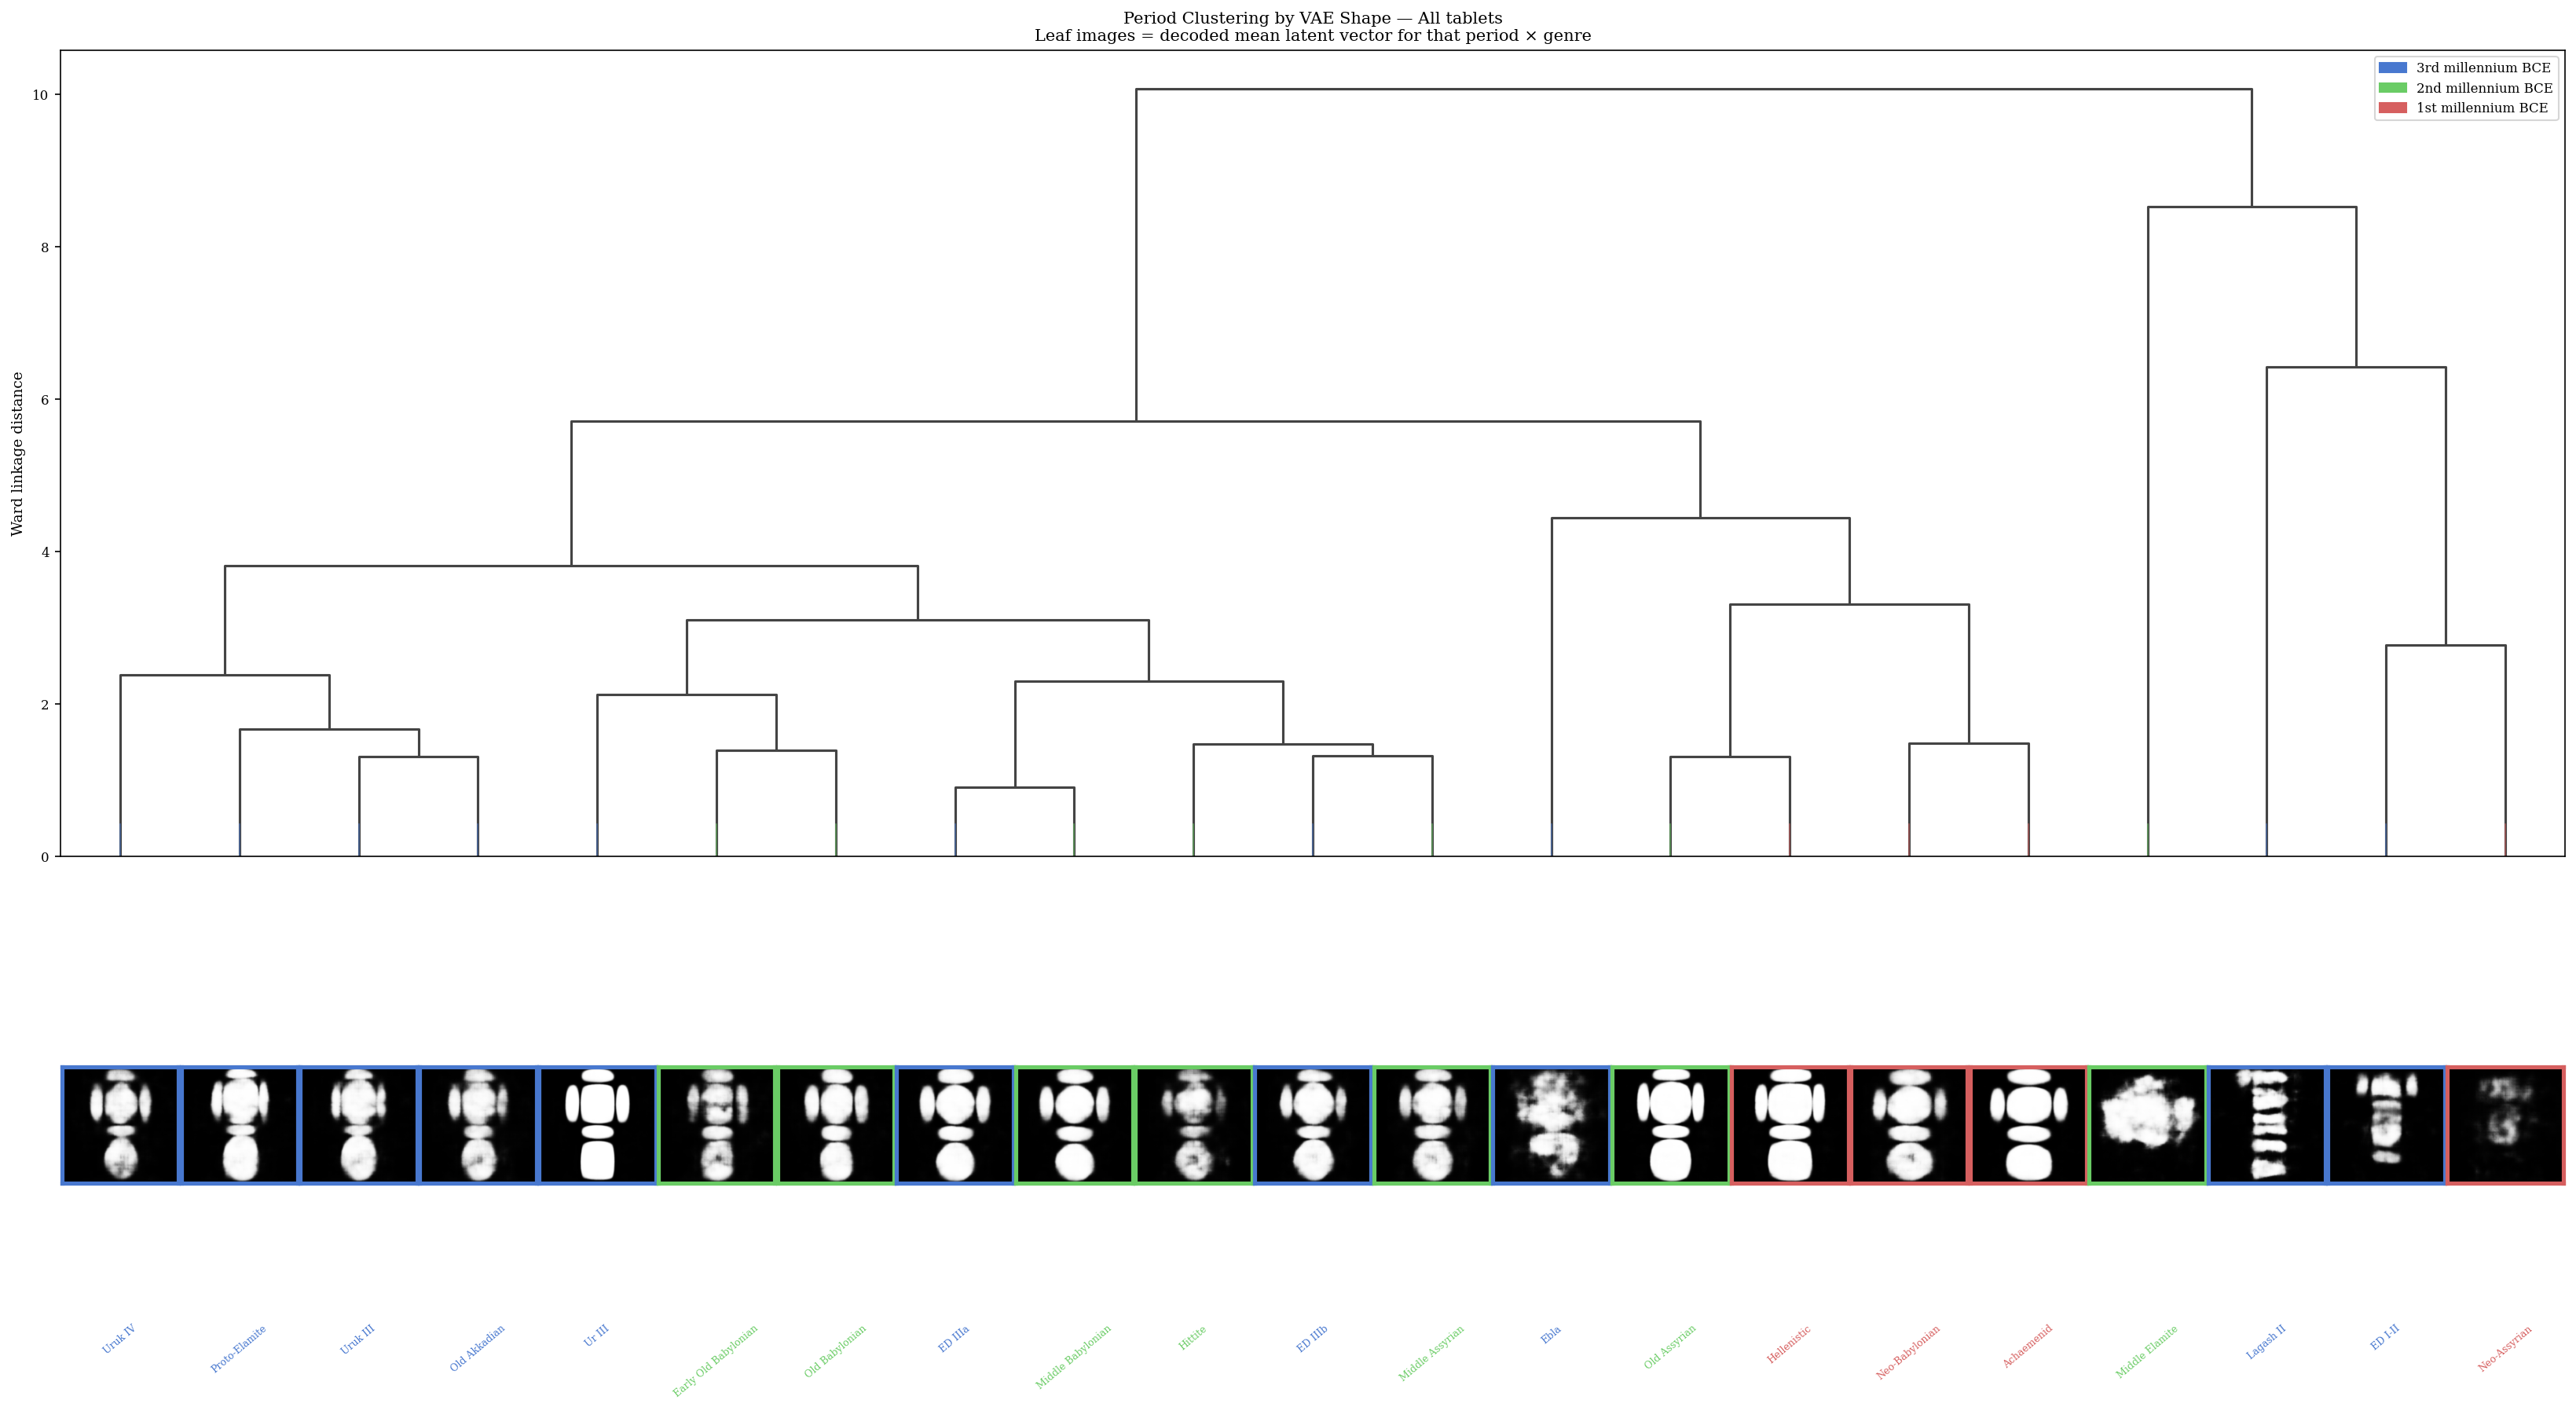

Saved: paper/figures/fig_vae_dendrogram_images_All_tablets.pdf


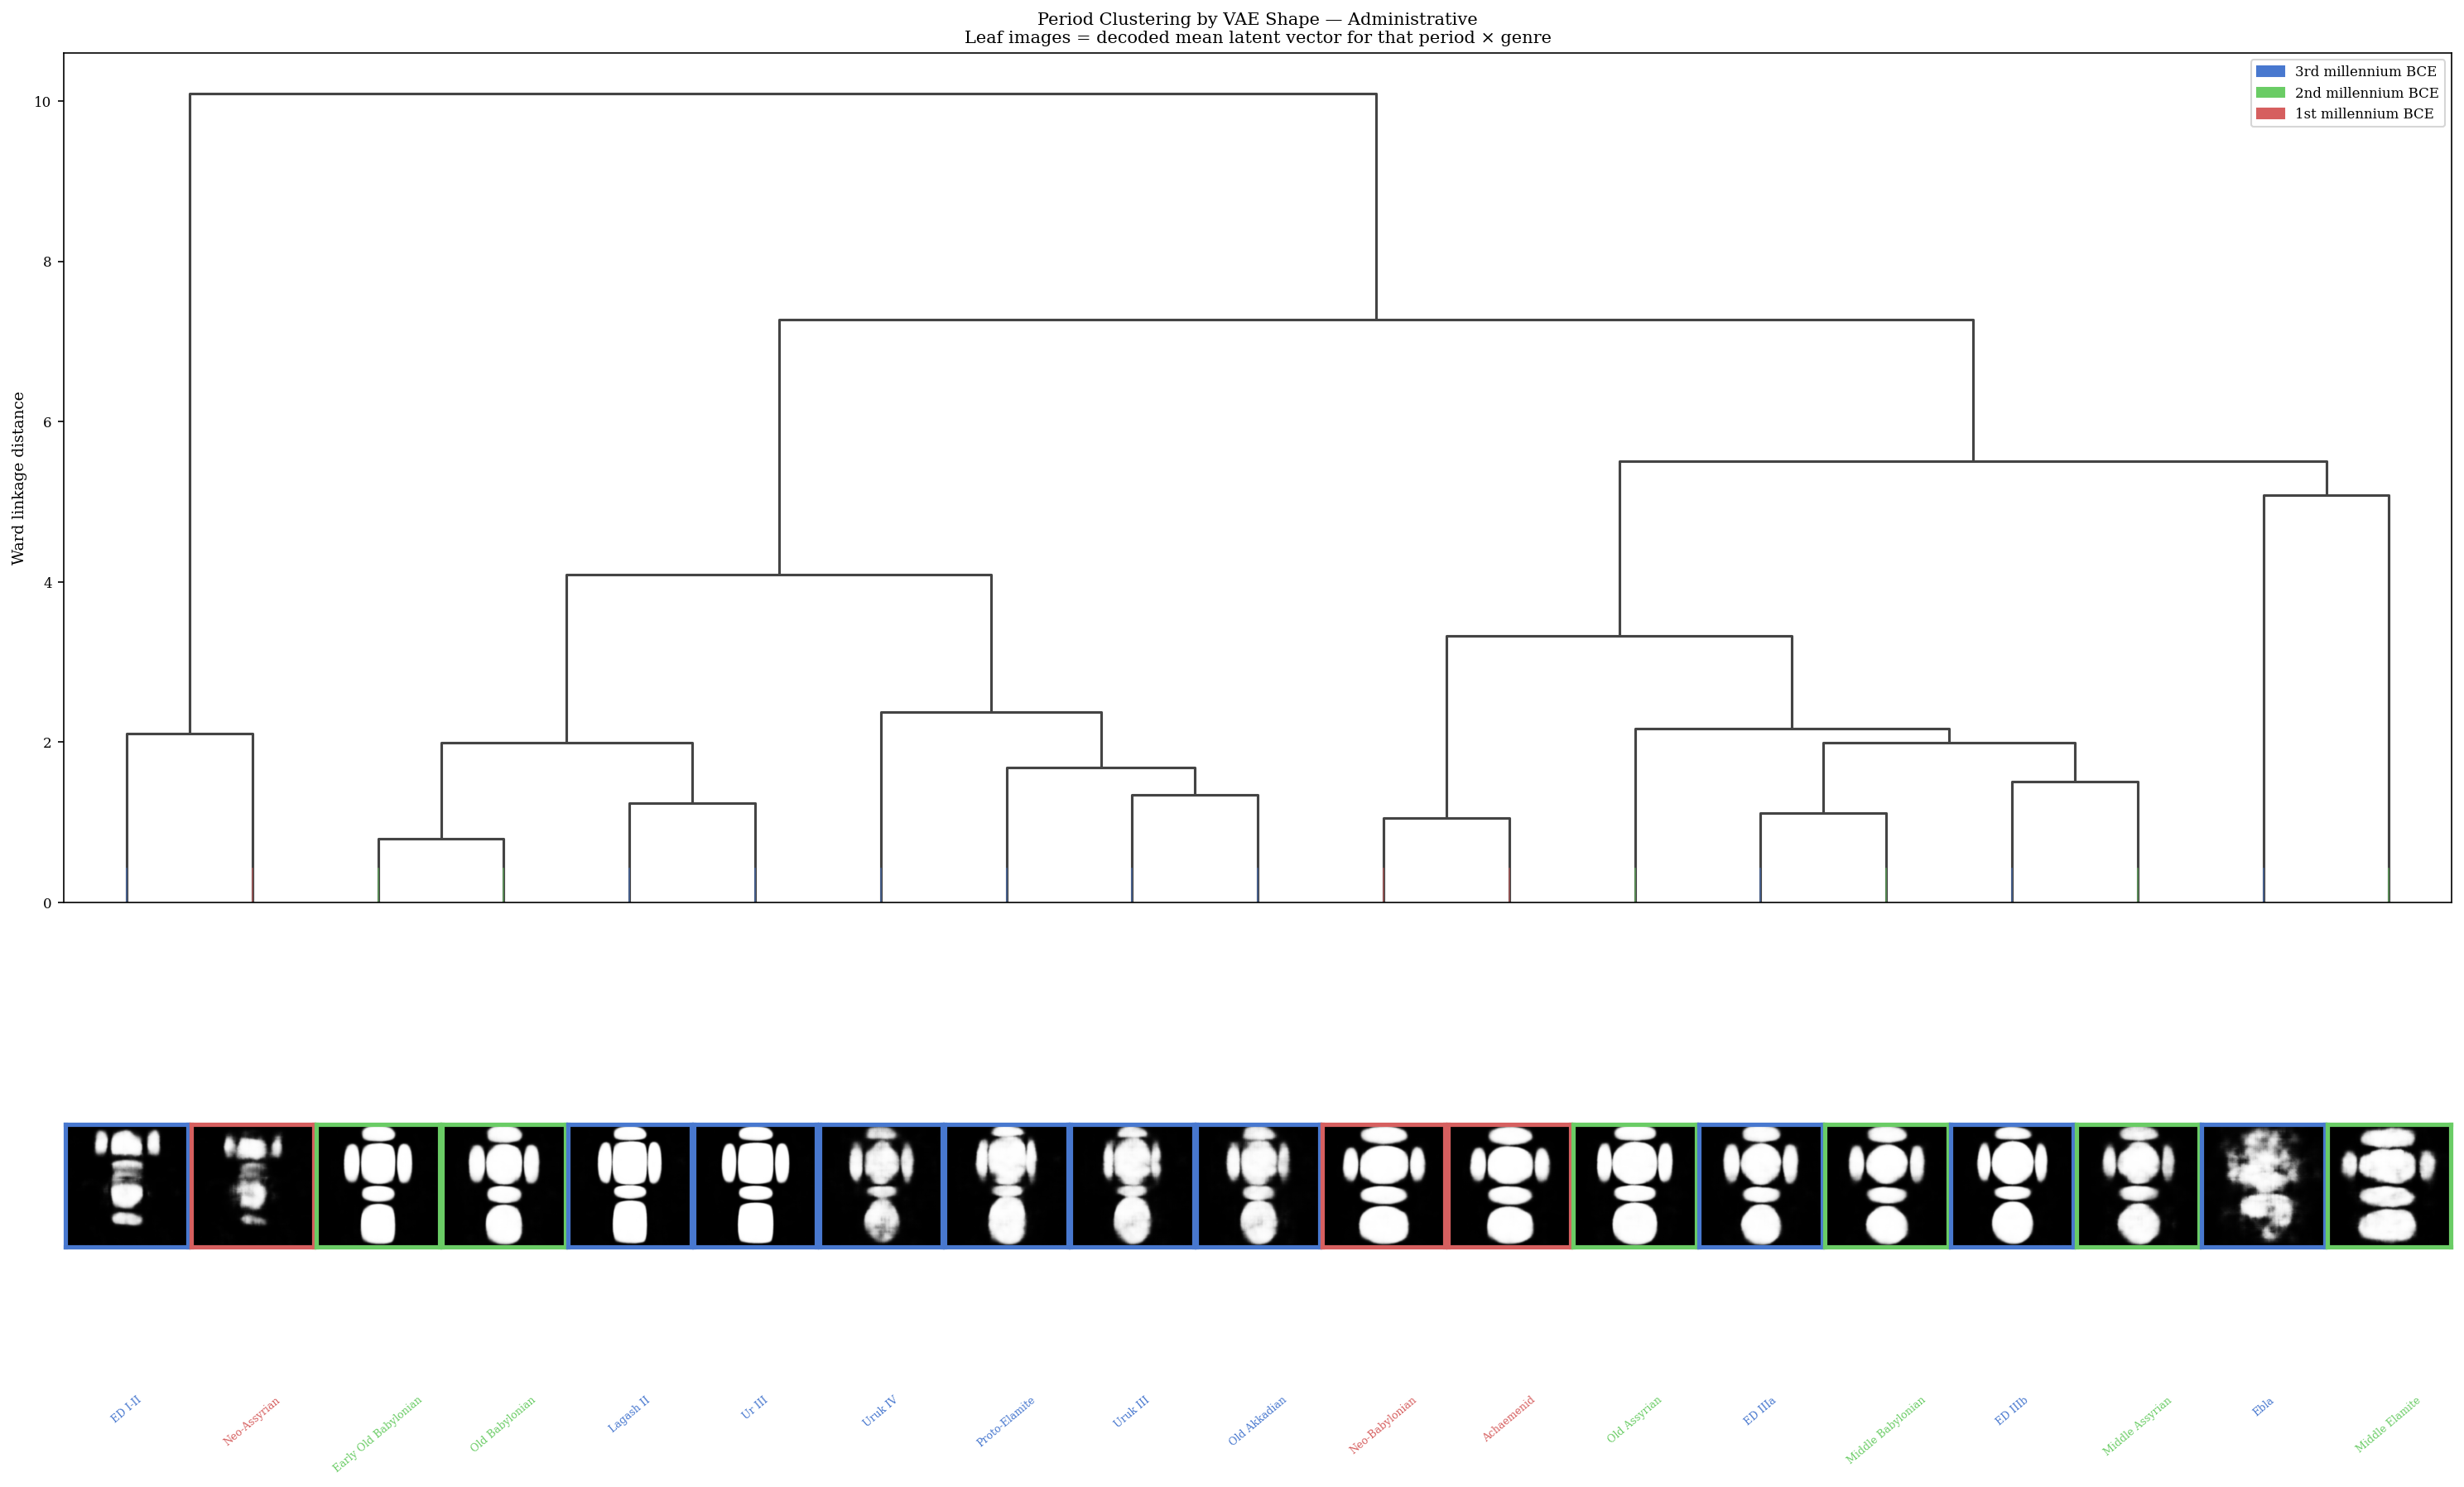

Saved: paper/figures/fig_vae_dendrogram_images_Administrative.pdf


In [19]:
# Dendrogram with decoded silhouettes — one per genre (Administrative is the most
# historically meaningful) plus All tablets.
# We use a two-panel layout: dendrogram on top, image strip on bottom (aligned by leaf order).
# This avoids the AnnotationBbox sizing problem and makes images large enough to read.

for dendro_label in ['All tablets', 'Administrative']:

    # Select the right decoded images
    img_dict = ROW_DECODED[dendro_label]
    # Only include periods that have decoded images
    periods_dend = [p for p in PERIOD_CHRON_ORDER
                    if p in mean_vecs.index and p in img_dict]

    # Mean vectors for these periods — for ALL tablets use the pre-computed mean_vecs,
    # for genre-specific use the genre_period_means
    if dendro_label == 'All tablets':
        X = mean_vecs.reindex(periods_dend)[VAE_DIMS].values
    else:
        X = np.array([genre_period_means[dendro_label][p] for p in periods_dend])

    Z = linkage(X, method='ward')

    # --- layout: dendrogram (top 65%) + image strip (bottom 35%) ---
    fig = plt.figure(figsize=(max(20, len(periods_dend) * 1.1), 12))
    ax_dend = fig.add_axes([0.05, 0.38, 0.92, 0.57])   # [left, bottom, width, height]
    ax_imgs = fig.add_axes([0.05, 0.00, 0.92, 0.35])   # image strip
    ax_imgs.axis('off')

    # Draw dendrogram — suppress leaf labels (we draw them manually below images)
    ddata = dendrogram(
        Z,
        labels=periods_dend,
        ax=ax_dend,
        leaf_rotation=0,
        leaf_font_size=0,
        color_threshold=0,
        above_threshold_color='#444444',
    )

    ax_dend.set_ylabel('Ward linkage distance')
    ax_dend.set_title(
        f'Period Clustering by VAE Shape — {dendro_label}\n'
        'Leaf images = decoded mean latent vector for that period × genre',
        fontsize=10
    )
    ax_dend.set_xticks([])

    # leaf order and x-positions in data coordinates
    leaf_labels_ordered = ddata['ivl']            # left-to-right period names
    n_leaves = len(leaf_labels_ordered)
    # Dendrogram leaf x-coords: 5, 15, 25, ... (10-unit spacing by matplotlib default)
    leaf_x_data = [5 + 10 * i for i in range(n_leaves)]

    # Convert data x to axes fraction for ax_dend
    x_min, x_max = ax_dend.get_xlim()
    def data_to_fig_x(x_d):
        ax_frac = (x_d - x_min) / (x_max - x_min)
        # ax_dend occupies [0.05, 0.05+0.92] in figure coords
        return 0.05 + ax_frac * 0.92

    # Place images in the image-strip axes using inset_axes
    IMG_SIZE_FRAC = 0.90 / n_leaves  # fraction of total image-strip width per image

    for i, period in enumerate(leaf_labels_ordered):
        fig_x_center = data_to_fig_x(leaf_x_data[i])
        # inset_axes: [left, bottom, width, height] in figure fraction
        # image strip occupies [0.05, 0.00, 0.92, 0.35] in figure fraction
        img_left   = fig_x_center - IMG_SIZE_FRAC / 2
        img_bottom = 0.07
        img_width  = IMG_SIZE_FRAC
        img_height = 0.24

        ax_i = fig.add_axes([img_left, img_bottom, img_width, img_height])
        img = img_dict[period]
        mil = to_millennium(period)
        ax_i.imshow(img, cmap='gray', vmin=0, vmax=1, aspect='equal')
        for spine in ax_i.spines.values():
            spine.set_edgecolor(PALETTE[mil])
            spine.set_linewidth(2.5)
        ax_i.set_xticks([]); ax_i.set_yticks([])

        # Period label below image
        fig.text(fig_x_center, 0.05, period,
                 ha='center', va='top', fontsize=6,
                 color=PALETTE[mil], rotation=40)

        # Thin connector line from bottom of dendrogram to top of image
        ax_dend.axvline(x=leaf_x_data[i], ymin=0, ymax=0.04,
                        color=PALETTE[mil], lw=0.8, alpha=0.6)

    handles = [mpatches.Patch(color=v, label=k) for k, v in PALETTE.items()]
    ax_dend.legend(handles=handles, loc='upper right', fontsize=8)

    outpath = f'{FIGURES_DIR}/fig_vae_dendrogram_images_{dendro_label.replace(" ","_")}.pdf'
    plt.savefig(outpath, bbox_inches='tight', dpi=200)
    plt.show()
    print(f'Saved: {outpath}')

## 7. Diachronic shape-descriptor trends

Plot the 5 shape descriptors measured at each period's mean vector
against chronological order. This is the VAE-analogue of the h/w ratio
diachronic trend plot in notebooks 2.2 and 2.3, but now for all
geometric properties simultaneously.

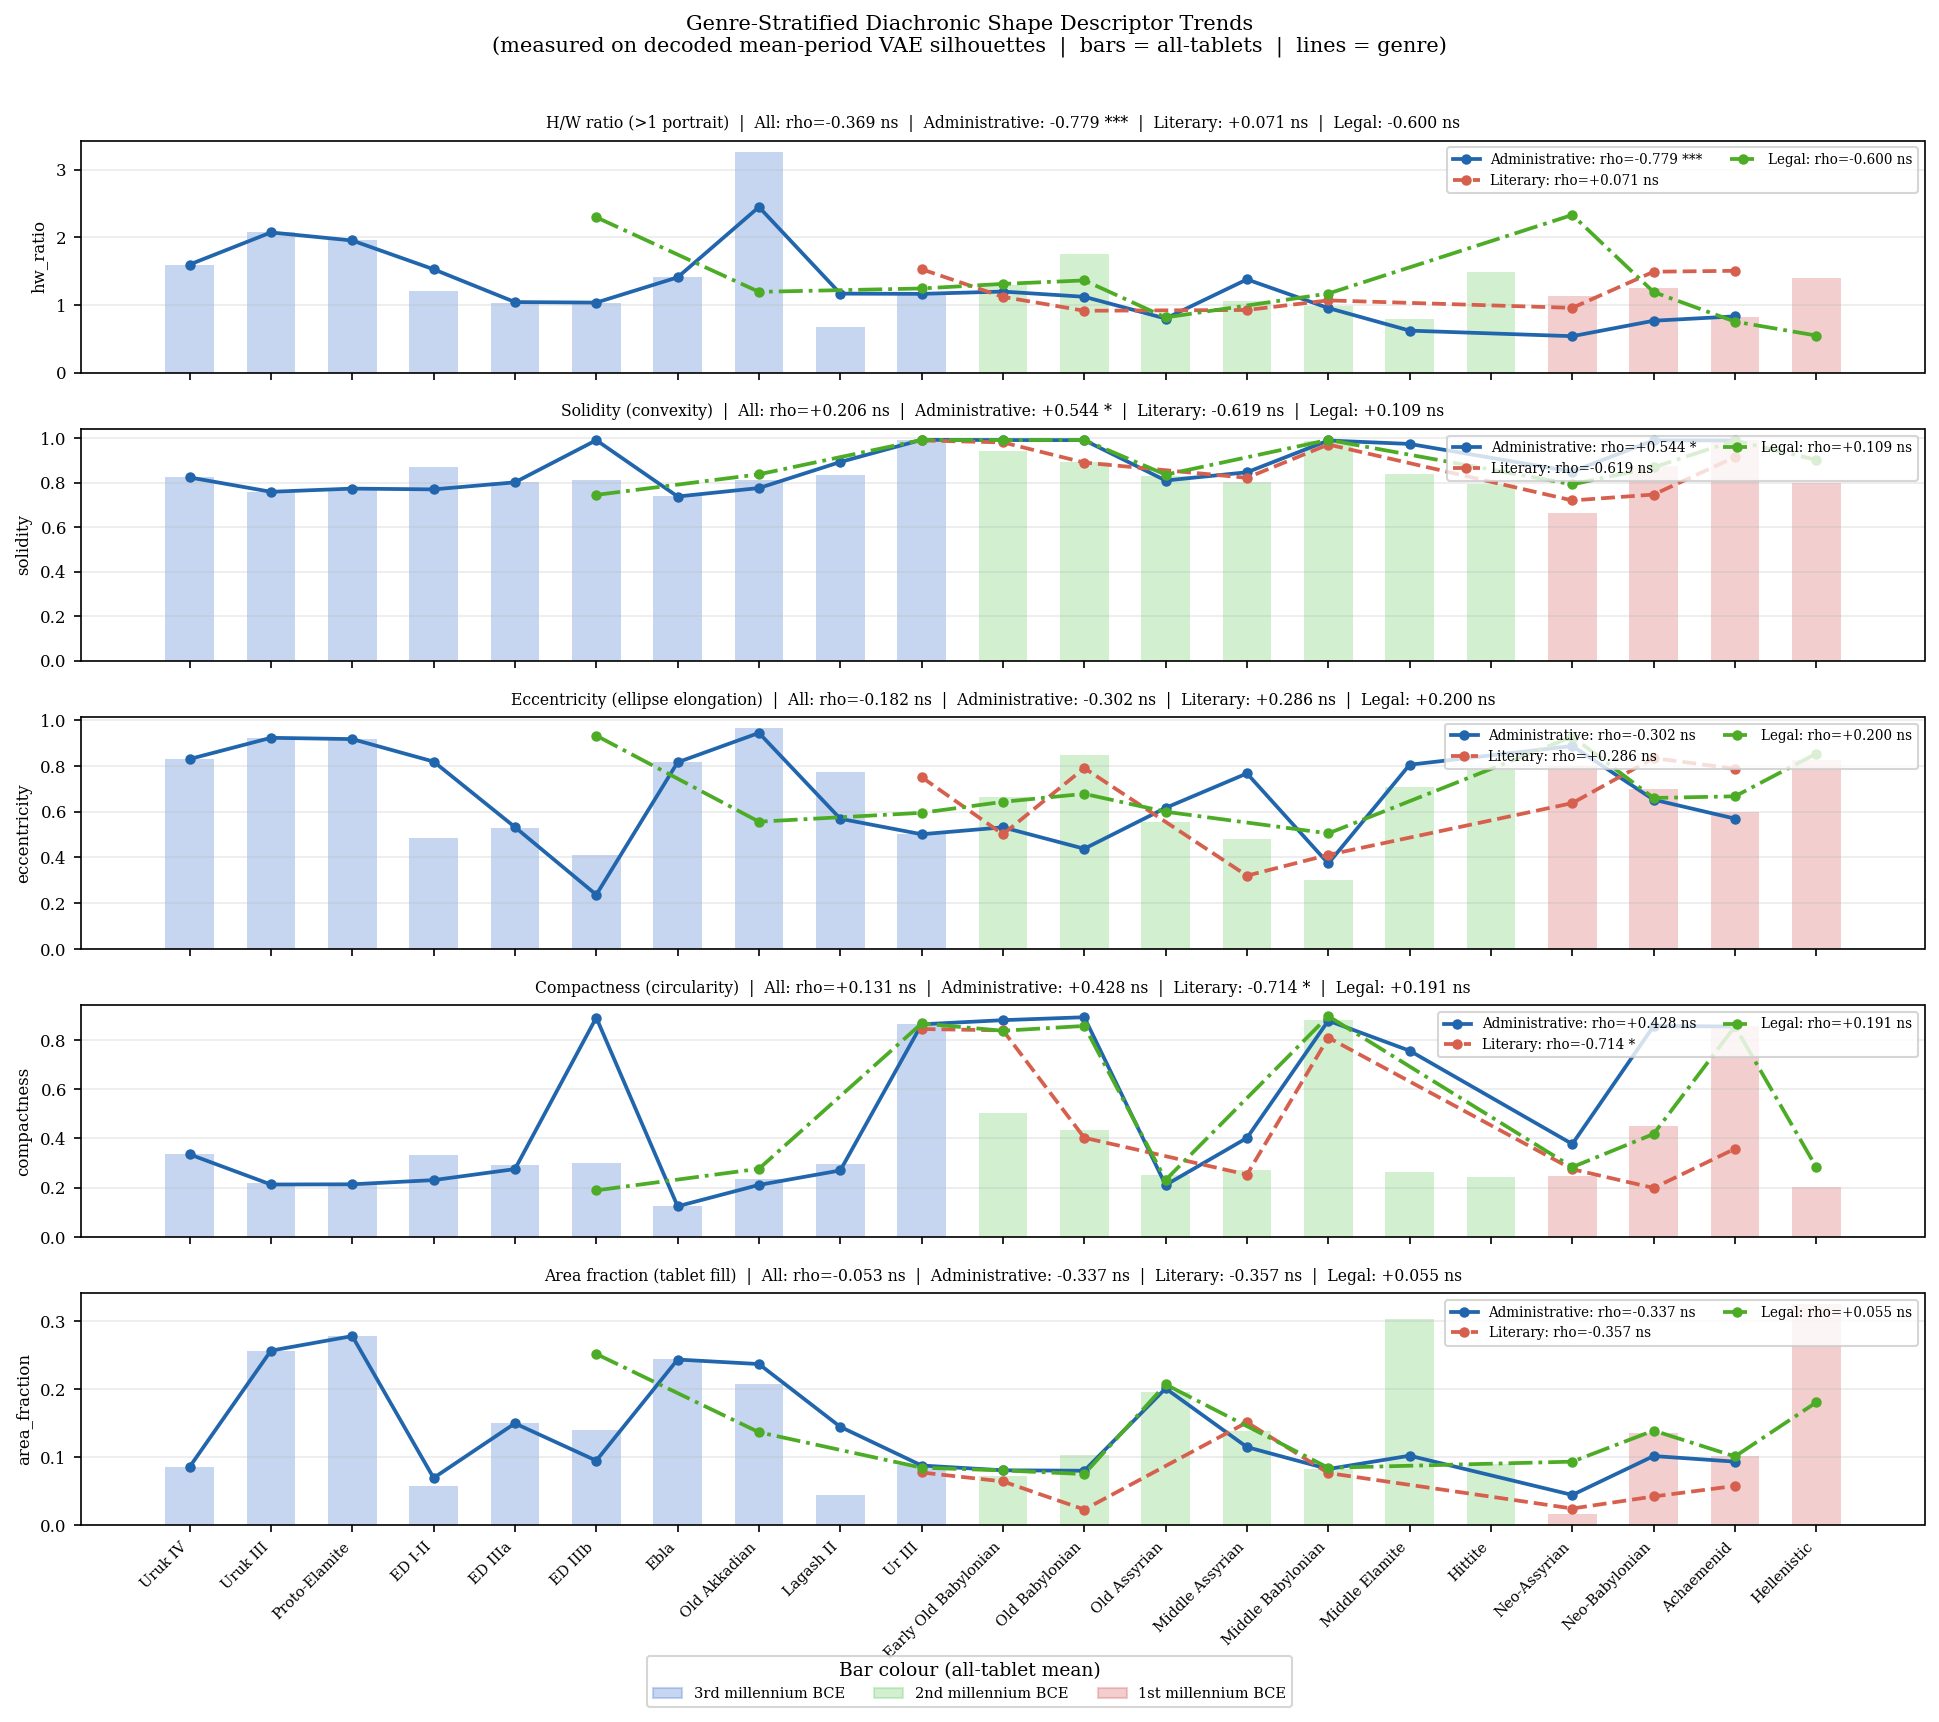

Saved: paper/figures/fig_vae_descriptor_trends_genre.pdf


In [20]:
# Genre-stratified diachronic shape descriptor trends
# For each of the 5 descriptors, plot one line per genre + all-tablets
# This shows whether each geometric property trends differently across scribal traditions

fig, axes = plt.subplots(len(DESCS), 1, figsize=(13, 11), sharex=True)
x_all = np.arange(len(periods_present))

for ax, desc, desc_color in zip(axes, DESCS, DESC_COLORS):
    # All-tablets line
    vals_all = np.array([shape_at_mean[p].get(desc, np.nan) for p in periods_present])
    colors_pts = [PALETTE.get(to_millennium(p), '#888') for p in periods_present]
    ax.bar(x_all, vals_all, color=colors_pts, alpha=0.3, width=0.6, zorder=1)
    valid = ~np.isnan(vals_all)
    if valid.sum() > 3:
        rho_all, p_all = spearmanr(x_all[valid], vals_all[valid])
        sig_all = '***' if p_all < 0.001 else ('**' if p_all < 0.01 else ('*' if p_all < 0.05 else 'ns'))
    else:
        rho_all, sig_all = np.nan, ''

    # Genre lines
    genre_rhos = {}
    for genre in FOCAL_GENRES:
        # periods where this genre has a decoded mean
        g_periods = [p for p in periods_present if p in decoded_genre[genre]]
        if len(g_periods) < 4:
            continue
        g_x    = [periods_present.index(p) for p in g_periods]
        g_vals = np.array([shape_genre[genre][p].get(desc, np.nan) for p in g_periods])
        valid_g = ~np.isnan(g_vals)
        if valid_g.sum() > 3:
            rho_g, p_g = spearmanr(np.array(g_x)[valid_g], g_vals[valid_g])
            sig_g = '***' if p_g < 0.001 else ('**' if p_g < 0.01 else ('*' if p_g < 0.05 else 'ns'))
            genre_rhos[genre] = (rho_g, sig_g)
            ax.plot(g_x, g_vals,
                    GENRE_LS[genre], color=GENRE_COLORS[genre],
                    lw=1.8, ms=4, marker='o', zorder=3,
                    label=f'{genre}: rho={rho_g:+.3f} {sig_g}')

    # Build title with all rho values
    title_parts = [f'All: rho={rho_all:+.3f} {sig_all}']
    for g, (r, s) in genre_rhos.items():
        title_parts.append(f'{g}: {r:+.3f} {s}')
    ax.set_title(
        f'{DESC_LABELS[desc]}  |  ' + '  |  '.join(title_parts),
        fontsize=7.5
    )
    ax.set_ylabel(desc, fontsize=8)
    ax.legend(fontsize=6.5, loc='upper right', ncol=2)
    ax.grid(axis='y', alpha=0.25)

axes[-1].set_xticks(x_all)
axes[-1].set_xticklabels(periods_present, rotation=45, ha='right', fontsize=7)

handles_mil = [mpatches.Patch(color=v, label=k, alpha=0.3) for k, v in PALETTE.items()]
fig.legend(handles=handles_mil, loc='lower center', ncol=3, fontsize=7,
           title='Bar colour (all-tablet mean)', bbox_to_anchor=(0.5, -0.02))

fig.suptitle(
    'Genre-Stratified Diachronic Shape Descriptor Trends\n'
    '(measured on decoded mean-period VAE silhouettes  |  bars = all-tablets  |  lines = genre)',
    fontsize=10, y=1.01
)
plt.tight_layout()
outpath = f'{FIGURES_DIR}/fig_vae_descriptor_trends_genre.pdf'
plt.savefig(outpath, bbox_inches='tight')
plt.show()
print(f'Saved: {outpath}')

## 8. Summary

In [21]:
print('=== NOTEBOOK 2.4b SUMMARY ===')
print()
print('Dimension interpretations (genre-controlled traversal):')
for dim in top_trend_dims:
    rho  = dim_stats.loc[dim, 'rho']
    eta2 = dim_stats.loc[dim, 'eta2']
    print(f'\n  {dim}: corpus rho={rho:+.3f}, eta2={eta2:.4f}')
    for label in TRAVERSAL_LABELS:
        if label in all_traversal_data.get(dim, {}):
            prim = all_traversal_data[dim][label].get('primary_descriptor', '?')
            direction = 'DECREASES' if rho < 0 else 'INCREASES'
            print(f'    {label:20s}: primary={prim:20s}  ({prim} {direction} 3rd→1st mil.)')

print()
print('Overall shape-descriptor trends (Spearman, all tablets):')
for desc in DESCS:
    vals = np.array([shape_at_mean[p].get(desc, np.nan) for p in periods_present])
    valid = ~np.isnan(vals)
    if valid.sum() > 3:
        rho, p_val = spearmanr(np.arange(len(vals))[valid], vals[valid])
        sig = '***' if p_val<0.001 else ('**' if p_val<0.01 else ('*' if p_val<0.05 else 'ns'))
        print(f'  {desc:20s}  rho={rho:+.3f}  {sig}')

print()
print('Genre × descriptor coverage (periods with ≥10 tablets decoded):')
for genre in FOCAL_GENRES:
    n = len(decoded_genre[genre])
    print(f'  {genre}: {n} periods')

print()
print('Figures saved:')
import glob as _g
saved = sorted(_g.glob(f'{FIGURES_DIR}/fig_vae_traversal_*_genre.pdf') +
               _g.glob(f'{FIGURES_DIR}/fig_vae_mean_period_timeline_genre.pdf') +
               _g.glob(f'{FIGURES_DIR}/fig_vae_dendrogram_images_*.pdf') +
               _g.glob(f'{FIGURES_DIR}/fig_vae_descriptor_trends_genre.pdf'))
for fn in saved:
    if os.path.exists(fn):
        print(f'  {os.path.basename(fn)}')

=== NOTEBOOK 2.4b SUMMARY ===

Dimension interpretations (genre-controlled traversal):

  X2: corpus rho=+0.654, eta2=0.0784
    All tablets         : primary=area_fraction         (area_fraction INCREASES 3rd→1st mil.)
    Administrative      : primary=area_fraction         (area_fraction INCREASES 3rd→1st mil.)
    Literary            : primary=solidity              (solidity INCREASES 3rd→1st mil.)
    Legal               : primary=area_fraction         (area_fraction INCREASES 3rd→1st mil.)

  X8: corpus rho=-0.573, eta2=0.0246
    All tablets         : primary=solidity              (solidity DECREASES 3rd→1st mil.)
    Administrative      : primary=area_fraction         (area_fraction DECREASES 3rd→1st mil.)
    Literary            : primary=solidity              (solidity DECREASES 3rd→1st mil.)
    Legal               : primary=solidity              (solidity DECREASES 3rd→1st mil.)

  X7: corpus rho=-0.430, eta2=0.4346
    All tablets         : primary=area_fraction         (ar